# Perform additional score analysis and generate figures

In [235]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from PIL import Image

In [2]:
main_dir = Path("/Users/isaiahhazelwood/Documents/rotations-2024/fraser-lab/DMS-data/")
raw_data_dir = main_dir / "raw-data/"
difference_dir = main_dir / "diff-scores/"
difference_tail_dir = main_dir / "diff-tail-scores/"

In [127]:
def load_scores(filename, directory=difference_dir, sep=","):
    """
    Load scores from a csv file as a dictionary of {(wt, position, mut): score}.
    filename: file name within the raw-data directory
    keep_cols: 0-indexed list of columns to record
    header: number of header lines to skip
    """
    scores = {}
    with open(directory / filename, "r") as f_scores:
        for line_num, line in enumerate(f_scores):
            if line_num < 1: # Skip header
                continue
            prot, ligand, wt, pos, mut, score = line.rstrip("\n").split(sep)
            pos = int(pos)
            score = float(score)
            scores[(wt, pos, mut)] = score
    return scores

In [128]:
cdk4_persky = load_scores("CDK4_Persky_2020.csv")
cdk6_persky = load_scores("CDK6_Persky_2020.csv")
EGFR_An = load_scores("EGFR_An_2022.csv")
EGFR_Hayes = load_scores("EGFR_Hayes_2024.csv")
EGFR_Kim = load_scores("EGFR_Kim_2024.csv")
MET_dEx14_Estevam = load_scores("MET_Estevam_2024_dEx14.csv")
MET_WT_Estevam = load_scores("MET_Estevam_2024_WT.csv")
SRC_Chakraborty = load_scores("SRC_Chakraborty_2024.csv")

## Location and count of mutations

Persky CDK4 mutations: 5713, 18.917218543046356
Persky CDK6 mutations: 6133, 18.87076923076923
An EGFR mutations: 3588, 19.085106382978722
Hayes EGFR mutations: 5869, 4.915410385259632
Kim EGFR mutations: 1991, 6.772108843537415
Estevam MET delEx14 mutations: 2911, 10.142857142857142
Estevam MET WT mutations: 4195, 14.616724738675957
Chakraborty SRC mutations: 2457, 9.828


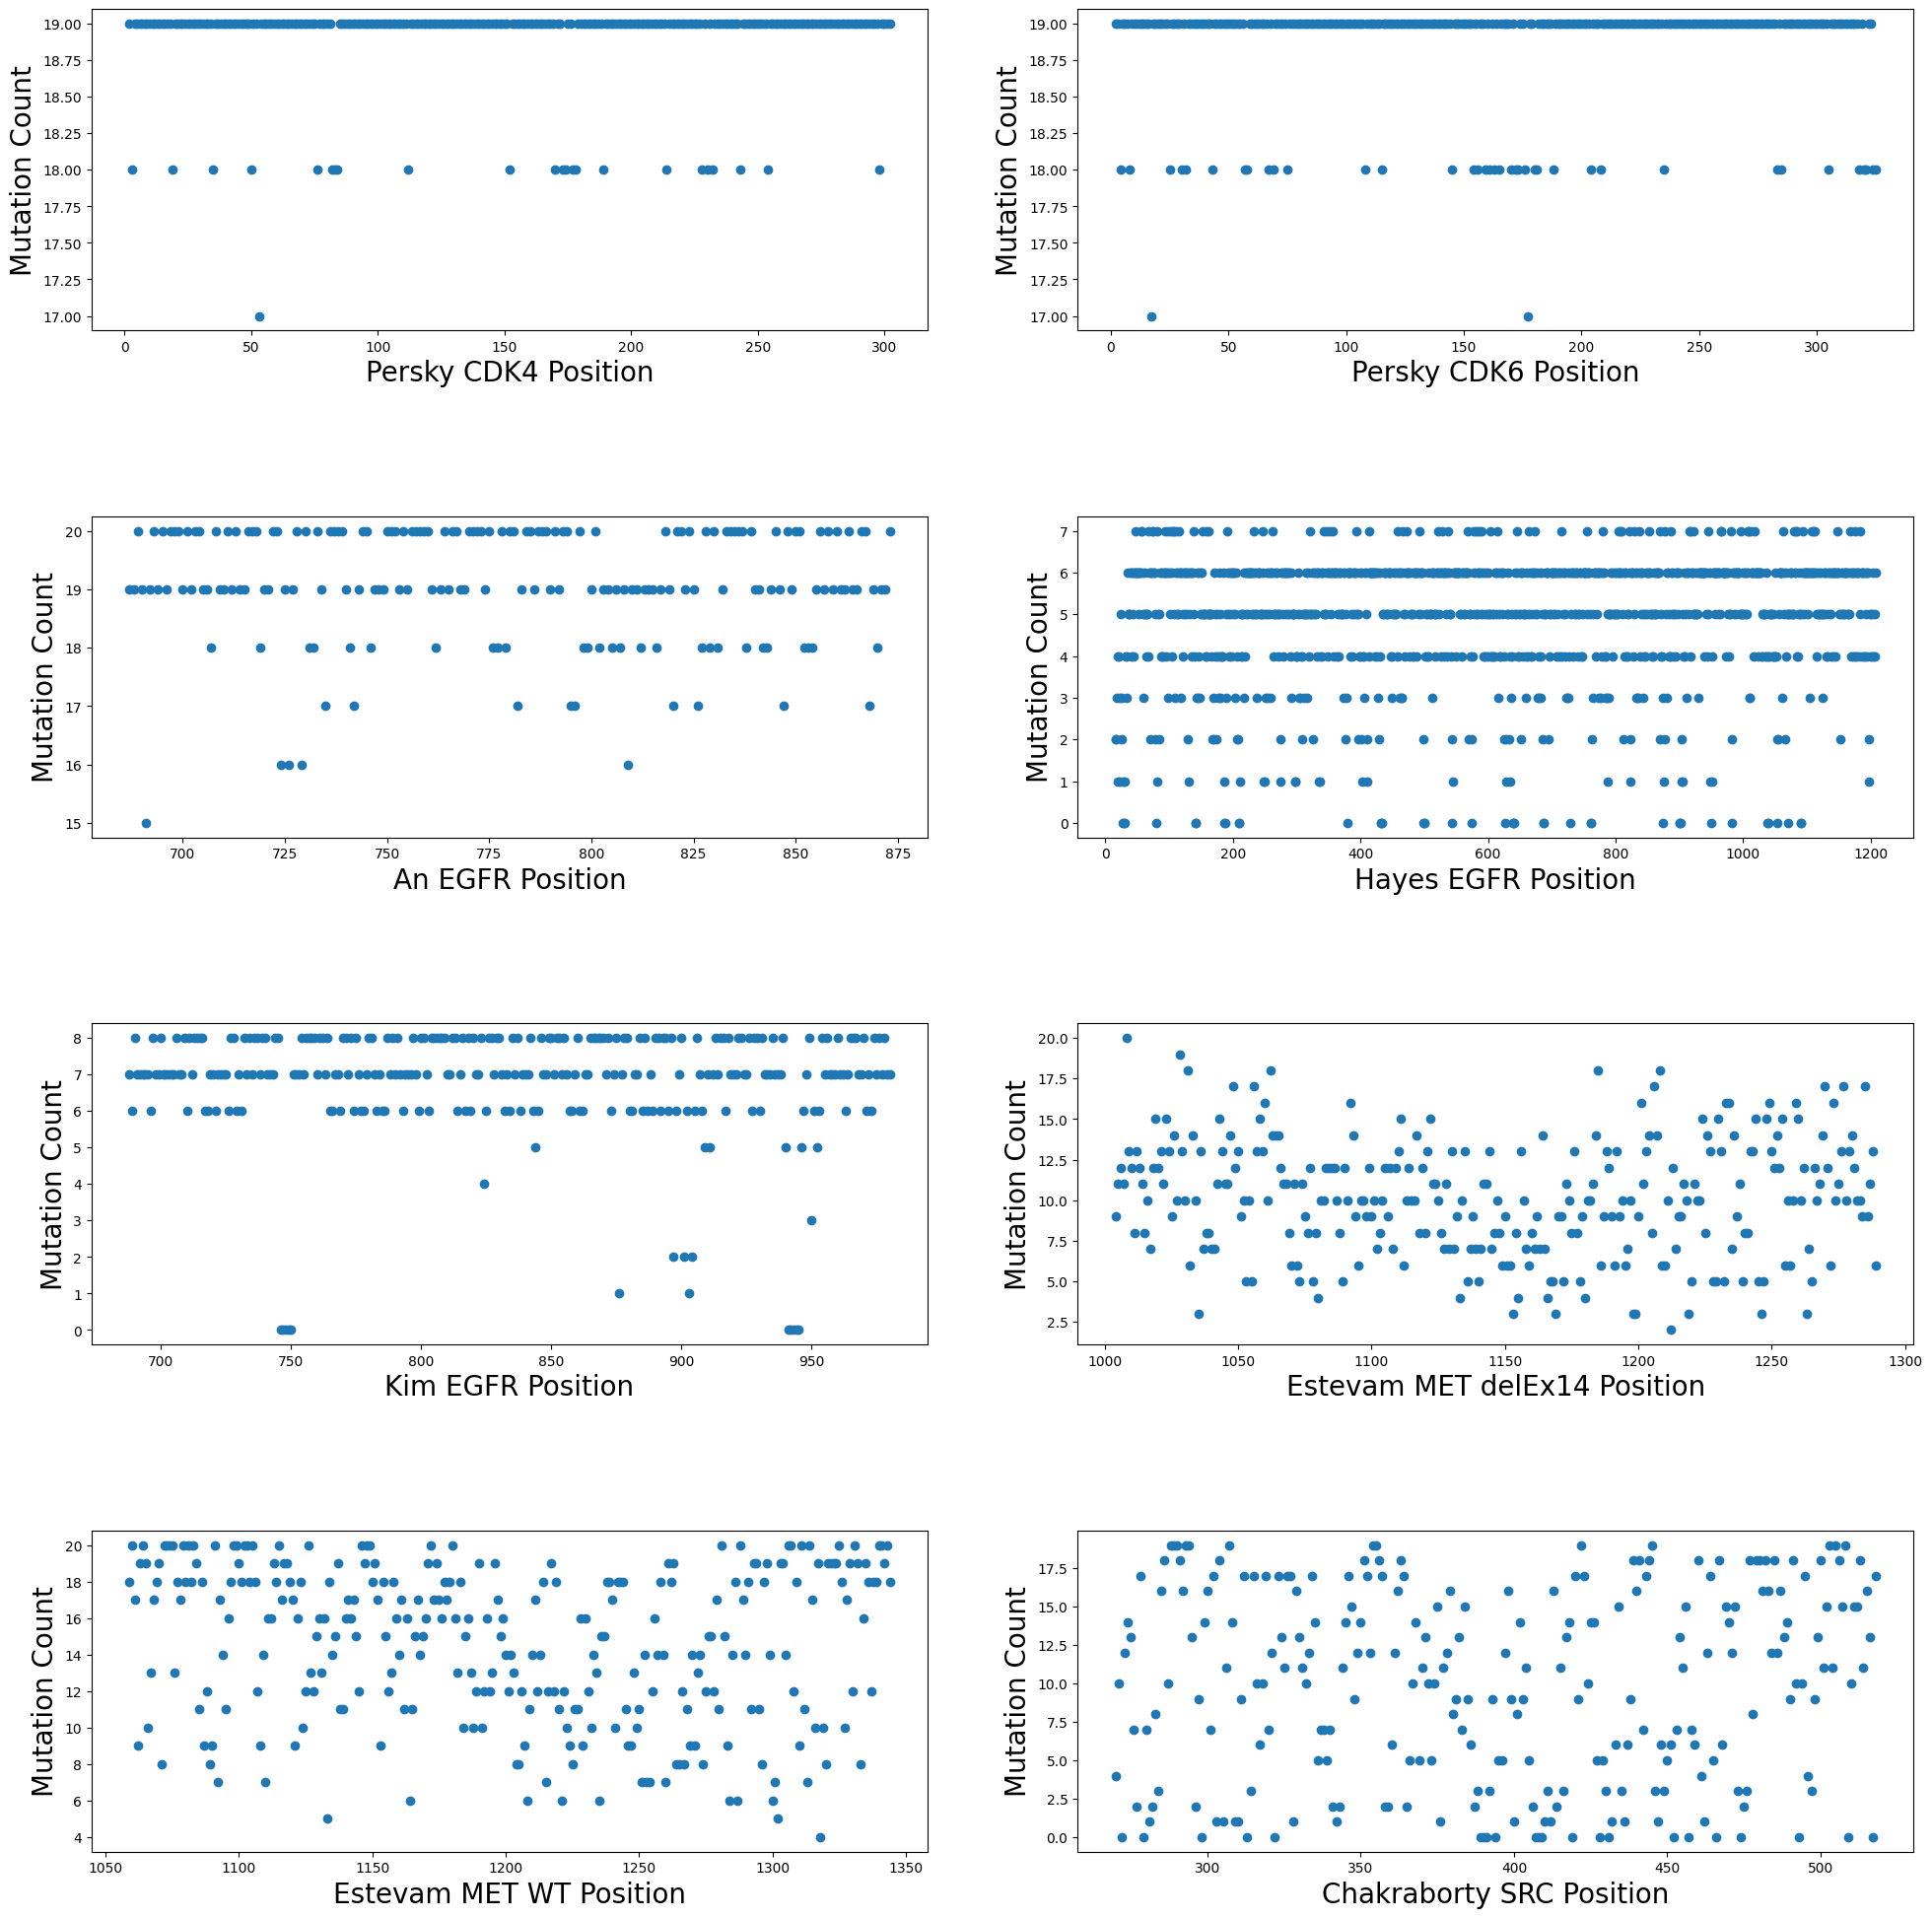

In [133]:
# Plot the number of mutations at each position in the genome
# Ensure datasets have sufficient coverage in the genome
def calculate_mut_freq(scores):
    pos_to_count = {}
    for wt, pos, mut in scores:
        if pos in pos_to_count:
            pos_to_count[pos] += 1
        else:
            pos_to_count[pos] = 1
    positions = []
    counts = []
    for position in range(min(pos_to_count.keys()), max(pos_to_count.keys())):
        positions.append(position)
        if position in pos_to_count:
            counts.append(pos_to_count[position])
        else:
            counts.append(0)
    return positions, counts

datasets = [cdk4_persky, cdk6_persky, EGFR_An, EGFR_Hayes, EGFR_Kim, MET_dEx14_Estevam, MET_WT_Estevam, SRC_Chakraborty]
dataset_titles = ["Persky CDK4", "Persky CDK6", "An EGFR", "Hayes EGFR", "Kim EGFR", "Estevam MET delEx14", 
                  "Estevam MET WT", "Chakraborty SRC"]

for i in range(len(datasets)):
    len_seq = max([pos for wt, pos, mut in datasets[i]]) - min([pos for wt, pos, mut in datasets[i]]) + 1
    print(f"{dataset_titles[i]} mutations: {len(datasets[i])}, {len(datasets[i]) / len_seq}")

fig, axs = plt.subplots(4, 2)
for i in range(len(datasets)):
    positions, counts = calculate_mut_freq(datasets[i])
    axs[i // 2, i % 2].scatter(positions, counts)
    axs[i // 2, i % 2].set_xlabel(f"{dataset_titles[i]} Position", size=20)
    axs[i // 2, i % 2].set_ylabel("Mutation Count", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(20)

## Save all mutations from score files as a FASTA

In [166]:
# This section is useful for generating FASTA files to generate ESM2 embeddings

seq_dir = main_dir / "seqs/"

def load_seq(filename, directory=seq_dir):
    with open(directory / filename, "r") as f_seq:
        header = f_seq.readline()
        seq = ""
        line = f_seq.readline()
        while line != "":
            seq += line.rstrip("\n")
            line = f_seq.readline()
    return seq

CDK4_seq = load_seq("CDK4.fasta")
CDK6_seq = load_seq("CDK6.fasta")
EGFR_seq = load_seq("EGFR.fasta")
SRC_seq = load_seq("SRC.fasta")
MET_seq = load_seq("MET.fasta")
MET_delEx14_seq = load_seq("MET_delEx14.fasta")

In [167]:
EGFR_T790M_seq = EGFR_seq[:790 - 1] + 'M' + EGFR_seq[790:]
# MET_delEx14_seq = MET_seq[:956 - 1] + MET_seq[1010:]
print(EGFR_T790M_seq)

MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFEDHFLSLQRMFNNCEVVLGNLEITYVQRNYDLSFLKTIQEVAGYVLIALNTVERIPLENLQIIRGNMYYENSYALAVLSNYDANKTGLKELPMRNLQEILHGAVRFSNNPALCNVESIQWRDIVSSDFLSNMSMDFQNHLGSCQKCDPSCPNGSCWGAGEENCQKLTKIICAQQCSGRCRGKSPSDCCHNQCAAGCTGPRESDCLVCRKFRDEATCKDTCPPLMLYNPTTYQMDVNPEGKYSFGATCVKKCPRNYVVTDHGSCVRACGADSYEMEEDGVRKCKKCEGPCRKVCNGIGIGEFKDSLSINATNIKHFKNCTSISGDLHILPVAFRGDSFTHTPPLDPQELDILKTVKEITGFLLIQAWPENRTDLHAFENLEIIRGRTKQHGQFSLAVVSLNITSLGLRSLKEISDGDVIISGNKNLCYANTINWKKLFGTSGQKTKIISNRGENSCKATGQVCHALCSPEGCWGPEPRDCVSCRNVSRGRECVDKCNLLEGEPREFVENSECIQCHPECLPQAMNITCTGRGPDNCIQCAHYIDGPHCVKTCPAGVMGENNTLVWKYADAGHVCHLCHPNCTYGCTGPGLEGCPTNGPKIPSIATGMVGALLLLLVVALGIGLFMRRRHIVRKRTLRRLLQERELVEPLTPSGEAPNQALLRILKETEFKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDNPHVCRLLGICLTSTVQLIMQLMPFGCLLDYVREHKDNIGSQYLLNWCVQIAKGMNYLEDRRLVHRDLAARNVLVKTPQHVKITDFGLAKLLGAEEKEYHAEGGKVPIKWMALESILHRIYTHQSDVWSYGVTVWELMTFGSKPYDGIPASEISSILEKGERLPQPPICTIDVYMIMVKCWMIDADSRPKFRELIIEFSKMARDPQRYLVIQGDERMHLPSPTDSNFYRA

In [202]:
EGFR_short_seq = EGFR_seq[650:]
EGFR_T790M_short_seq = EGFR_T790M_seq[650:]
MET_short_seq = MET_seq[1050:]
MET_delEx14_short_seq = MET_delEx14_seq[995:]
print(EGFR_short_seq)
print(EGFR_T790M_short_seq)
print(MET_short_seq)
print(MET_delEx14_short_seq)

VGALLLLLVVALGIGLFMRRRHIVRKRTLRRLLQERELVEPLTPSGEAPNQALLRILKETEFKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDNPHVCRLLGICLTSTVQLITQLMPFGCLLDYVREHKDNIGSQYLLNWCVQIAKGMNYLEDRRLVHRDLAARNVLVKTPQHVKITDFGLAKLLGAEEKEYHAEGGKVPIKWMALESILHRIYTHQSDVWSYGVTVWELMTFGSKPYDGIPASEISSILEKGERLPQPPICTIDVYMIMVKCWMIDADSRPKFRELIIEFSKMARDPQRYLVIQGDERMHLPSPTDSNFYRALMDEEDMDDVVDADEYLIPQQGFFSSPSTSRTPLLSSLSATSNNSTVACIDRNGLQSCPIKEDSFLQRYSSDPTGALTEDSIDDTFLPVPEYINQSVPKRPAGSVQNPVYHNQPLNPAPSRDPHYQDPHSTAVGNPEYLNTVQPTCVNSTFDSPAHWAQKGSHQISLDNPDYQQDFFPKEAKPNGIFKGSTAENAEYLRVAPQSSEFIGA
VGALLLLLVVALGIGLFMRRRHIVRKRTLRRLLQERELVEPLTPSGEAPNQALLRILKETEFKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDNPHVCRLLGICLTSTVQLIMQLMPFGCLLDYVREHKDNIGSQYLLNWCVQIAKGMNYLEDRRLVHRDLAARNVLVKTPQHVKITDFGLAKLLGAEEKEYHAEGGKVPIKWMALESILHRIYTHQSDVWSYGVTVWELMTFGSKPYDGIPASEISSILEKGERLPQPPICTIDVYMIMVKCWMIDADSRPKFRELIIEFSKMARDPQRYLVIQGDERMHLPSPTDSNFYRALMDEEDMDDVVDADEYLIPQQGFFSSPSTSRTPLLSSLSATSNNSTVACIDRNGLQSCPIKEDSFLQRYSSDPTGALTEDSIDDTFLPV

In [168]:
def load_scores(filename, directory=difference_dir, sep=","):
    """
    Load scores from a csv file as a dictionary of {(wt, position, mut): score}.
    filename: file name within the raw-data directory
    keep_cols: 0-indexed list of columns to record
    header: number of header lines to skip
    """
    scores = {}
    with open(directory / filename, "r") as f_scores:
        for line_num, line in enumerate(f_scores):
            if line_num < 1: # Skip header
                continue
            prot, ligand, wt, pos, mut, score = line.rstrip("\n").split(sep)
            pos = int(pos)
            score = float(score)
            scores[(prot, ligand, wt, pos, mut)] = score
    return scores

cdk4_persky = load_scores("CDK4_Persky_2020.csv")
cdk6_persky = load_scores("CDK6_Persky_2020.csv")
EGFR_An = load_scores("EGFR_An_2022.csv")
EGFR_Hayes = load_scores("EGFR_Hayes_2024.csv")
EGFR_Kim = load_scores("EGFR_Kim_2024.csv")
MET_dEx14_Estevam = load_scores("MET_Estevam_2024_dEx14.csv")
MET_WT_Estevam = load_scores("MET_Estevam_2024_WT.csv")
SRC_Chakraborty = load_scores("SRC_Chakraborty_2024.csv")

In [169]:
# Check mutants against the sequence

seq_dict = {"CDK4": CDK4_seq,
            "CDK6": CDK6_seq,
            "EGFR": EGFR_seq,
            "EGFR_T790M": EGFR_T790M_seq, 
            "SRC": SRC_seq, 
            "MET_WT": MET_seq, 
            "MET_dEx14": MET_delEx14_seq}

mutants = {}
for mutant_dict in (cdk4_persky, cdk6_persky, EGFR_An, EGFR_Hayes, EGFR_Kim,
                    MET_WT_Estevam, MET_dEx14_Estevam, SRC_Chakraborty):
    for mutant in mutant_dict:
        prot, ligand, wt, pos, mut_aa = mutant
        # if prot == "MET_dEx14" and pos >= 956:
        #     if pos <= 1010:
        #         raise Exception(f"Position {pos} in MET_dEx14")
        #     pos -= 55
        assert seq_dict[prot][pos - 1] == wt or (prot == "EGFR_T790M" and pos == 790 and wt == "T"), (mutant, seq_dict[prot][pos - 1])
        
        mutant_id = f"{prot}_{wt}{pos}{mut_aa}"
        if mutant_id not in mutants:
            mutants[mutant_id] = seq_dict[prot][:pos - 1] + mut_aa + seq_dict[prot][pos:]
                
print(len(mutants))

32165


In [184]:
print(min(pos for prot, ligand, wt, pos, mut in SRC_Chakraborty))
print(max(pos for prot, ligand, wt, pos, mut in SRC_Chakraborty))

270
519


In [185]:
# Write CSV files containing only the mutation (no scores)
mut_list_dir = main_dir / "mut-lists"
for prot in seq_dict.keys():
    with open(mut_list_dir / f"{prot}.csv", "w") as f_prot:
        f_prot.write("Prot,Mut_key,WT,Pos,Mut\n")
        for mutant_id in mutants:
            prot_key = "_".join(mutant_id.split("_")[:-1])
            if prot_key == prot:
                mut_key = mutant_id.split("_")[-1]
                wt, pos, mut_aa = mut_key[:1], mut_key[1:-1], mut_key[-1:]
                # if int(pos) > 1024:
                #     pass
                    # print(f"Skipping {prot_key},{mut_key},{wt},{pos},{mut_aa}")
                # else:
                f_prot.write(f"{prot_key},{mut_key},{wt},{pos},{mut_aa}\n")


In [204]:
# ESM1b has a token limit (1024). This code adjusts the set of mutations to crop the sequences appropriately

EGFR_An_shortened = {}
for prot, ligand, wt, pos, mut in EGFR_An:
    if pos > 650:
        EGFR_An_shortened[(prot, ligand, wt, pos - 650, mut)] = EGFR_An[(prot, ligand, wt, pos, mut)]

EGFR_Hayes_shortened = {}
for prot, ligand, wt, pos, mut in EGFR_Hayes:
    if pos > 650:
        EGFR_Hayes_shortened[(prot, ligand, wt, pos - 650, mut)] = EGFR_Hayes[(prot, ligand, wt, pos, mut)]

EGFR_Kim_shortened = {}
for prot, ligand, wt, pos, mut in EGFR_Kim:
    if pos > 650:
        EGFR_Kim_shortened[(prot, ligand, wt, pos - 650, mut)] = EGFR_Kim[(prot, ligand, wt, pos, mut)]

MET_WT_Estevam_shortened = {}
for prot, ligand, wt, pos, mut in MET_WT_Estevam:
    if pos > 1050:
        MET_WT_Estevam_shortened[(prot, ligand, wt, pos - 1050, mut)] = MET_WT_Estevam[(prot, ligand, wt, pos, mut)]

MET_dEx14_Estevam_shortened = {}
for prot, ligand, wt, pos, mut in MET_dEx14_Estevam:
    if pos > 995:
        MET_dEx14_Estevam_shortened[(prot, ligand, wt, pos - 995, mut)] = MET_dEx14_Estevam[(prot, ligand, wt, pos, mut)]

seq_dict = {"CDK4": CDK4_seq,
            "CDK6": CDK6_seq,
            "EGFR": EGFR_short_seq,
            "EGFR_T790M": EGFR_T790M_short_seq, 
            "SRC": SRC_seq, 
            "MET_WT": MET_short_seq, 
            "MET_dEx14": MET_delEx14_short_seq}

mutants = {}
for mutant_dict in (cdk4_persky, cdk6_persky, EGFR_An_shortened, 
                    EGFR_Hayes_shortened, EGFR_Kim_shortened,
                    MET_WT_Estevam_shortened, MET_dEx14_Estevam_shortened,
                    SRC_Chakraborty):
    for mutant in mutant_dict:
        prot, ligand, wt, pos, mut_aa = mutant
        # if prot == "MET_dEx14" and pos >= 956:
        #     if pos <= 1010:
        #         raise Exception(f"Position {pos} in MET_dEx14")
        #     pos -= 55
        assert seq_dict[prot][pos - 1] == wt or (prot == "EGFR_T790M" and pos == 140 and wt == "T"), (mutant, seq_dict[prot][pos - 1])
        
        mutant_id = f"{prot}_{wt}{pos}{mut_aa}"
        if mutant_id not in mutants:
            mutants[mutant_id] = seq_dict[prot][:pos - 1] + mut_aa + seq_dict[prot][pos:]

# Write mutation lists for the cropped sequences
mut_list_dir = main_dir / "mut-lists"
for prot in seq_dict.keys():
    with open(mut_list_dir / f"{prot}_max1024.csv", "w") as f_prot:
        f_prot.write("Prot,Mut_key,WT,Pos,Mut\n")
        for mutant_id in mutants:
            prot_key = "_".join(mutant_id.split("_")[:-1])
            if prot_key == prot:
                mut_key = mutant_id.split("_")[-1]
                wt, pos, mut_aa = mut_key[:1], mut_key[1:-1], mut_key[-1:]
                if int(pos) > 1024:
                    continue
                f_prot.write(f"{prot_key},{mut_key},{wt},{pos},{mut_aa}\n")

In [151]:
# Write the mutated fasta sequences
with open(mut_list_dir / "all_muts.fasta", "w") as f_fasta:
    for mutant_key in mutants:
        f_fasta.write(f">{mutant_key}\n")
        for i in range(len(mutants[mutant_key]) // 60 + 1):
            f_fasta.write(f"{mutants[mutant_key][60*i:60*(i+1)].replace("*", "")}\n")

In [150]:
print(max(len(mutants[mutant_key]) for mutant_key in mutants))

1390


## Find correlation of scores between datasets

In [293]:
# Check whether the raw data correlates across normalized and raw scores

def load_scores(filename, directory=difference_dir, sep=","):
    """
    Load scores from a csv file as a dictionary of {(wt, position, mut): score}.
    filename: file name within the raw-data directory
    keep_cols: 0-indexed list of columns to record
    header: number of header lines to skip
    """
    scores = {}
    with open(directory / filename, "r") as f_scores:
        for line_num, line in enumerate(f_scores):
            if line_num < 1: # Skip header
                continue
            prot, ligand, wt, pos, mut, score = line.rstrip("\n").split(sep)
            pos = int(pos)
            score = float(score)
            scores[(prot, ligand, wt, pos, mut)] = score
    return scores

In [294]:
cdk4_persky = load_scores("CDK4_Persky_2020.csv")
cdk6_persky = load_scores("CDK6_Persky_2020.csv")
EGFR_An = load_scores("EGFR_An_2022.csv")
EGFR_Hayes = load_scores("EGFR_Hayes_2024.csv")
EGFR_Kim = load_scores("EGFR_Kim_2024.csv")
MET_dEx14_Estevam = load_scores("MET_Estevam_2024_dEx14.csv")
MET_WT_Estevam = load_scores("MET_Estevam_2024_WT.csv")
SRC_Chakraborty = load_scores("SRC_Chakraborty_2024.csv")

In [295]:
# Extract the mutations associated with each ligand treatment

def extract_ligand(data, extract_prot, extract_ligand):
    filtered_data =  {(wt, pos, mut): data[(prot, ligand, wt, pos, mut)] 
                      for prot, ligand, wt, pos, mut in data 
                      if ligand == extract_ligand and prot == extract_prot}
    assert len(filtered_data) > 0
    return filtered_data

CDK4_Pal_persky = extract_ligand(cdk4_persky, "CDK4", "Pal_2uM")

CDK6_Pal_persky = extract_ligand(cdk6_persky, "CDK6", "Pal_2uM")

EGFR_Afa_An = extract_ligand(EGFR_An, "EGFR", "Afa_50nM")
EGFR_Erl_An = extract_ligand(EGFR_An, "EGFR", "Erl_600nM")
EGFR_Gef_An = extract_ligand(EGFR_An, "EGFR", "Gef_600nM")
EGFR_Ico_An = extract_ligand(EGFR_An, "EGFR", "Ico_600nM")
EGFR_Osi_An = extract_ligand(EGFR_An, "EGFR", "Osi_200nM")

EGFR_Erl_Hayes = extract_ligand(EGFR_Hayes, "EGFR", "Erl_200nM")

EGFR_Afa_Kim = extract_ligand(EGFR_Kim, "EGFR", "Afa_3nM")
EGFR_Osi_Kim = extract_ligand(EGFR_Kim, "EGFR", "Osi_8nM")

EGFR_T790M_Osi_Kim = extract_ligand(EGFR_Kim, "EGFR_T790M", "Osi_8nM")

MET_dEx14_Savo_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "Savo_1.51nM")
MET_dEx14_NVP_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "NVP_45.1nM")
MET_dEx14_Tiv_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "Tiv_2.55uM")
MET_dEx14_Camp_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "Camp_6.70nM")
MET_dEx14_A458_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "A458_534nM")
MET_dEx14_Cabo_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "Cabo_71nM")
MET_dEx14_Gle_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "Gle_324nM")
MET_dEx14_Crizo_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "Crizo_21.9nM")
MET_dEx14_Glu_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "Glu_31.3nM")
MET_dEx14_Mere_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "Mere_47.3nM")
MET_dEx14_Tepo_Estevam = extract_ligand(MET_dEx14_Estevam, "MET_dEx14", "Tepo_1.74nM")

MET_WT_Savo_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "Savo_1.51nM")
MET_WT_NVP_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "NVP_45.1nM")
MET_WT_Tiv_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "Tiv_2.55uM")
MET_WT_Camp_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "Camp_6.70nM")
MET_WT_A458_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "A458_534nM")
MET_WT_Cabo_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "Cabo_71nM")
MET_WT_Gle_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "Gle_324nM")
MET_WT_Crizo_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "Crizo_21.9nM")
MET_WT_Glu_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "Glu_31.3nM")
MET_WT_Mere_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "Mere_47.3nM")
MET_WT_Tepo_Estevam = extract_ligand(MET_WT_Estevam, "MET_WT", "Tepo_1.74nM")

SRC_Dis25uM_Chakraborty = extract_ligand(SRC_Chakraborty, "SRC", "Dis_25uM")
SRC_Dis100uM_Chakraborty = extract_ligand(SRC_Chakraborty, "SRC", "Dis_100uM")
SRC_Inhib1_Chakraborty = extract_ligand(SRC_Chakraborty, "SRC", "Inhib1_8uM")
SRC_Inhib2_Chakraborty = extract_ligand(SRC_Chakraborty, "SRC", "Inhib2_2uM")
SRC_Inhib4_Chakraborty = extract_ligand(SRC_Chakraborty, "SRC", "Inhib4_0.8uM")

In [296]:
MET_WT_datasets = [MET_WT_Tiv_Estevam, MET_WT_Camp_Estevam, MET_WT_Crizo_Estevam, 
                   MET_WT_Tepo_Estevam, MET_WT_Glu_Estevam, MET_WT_Savo_Estevam,
                   MET_WT_NVP_Estevam, MET_WT_Cabo_Estevam, MET_WT_Mere_Estevam,
                   MET_WT_Gle_Estevam, MET_WT_A458_Estevam]
MET_dEx14_datasets = [MET_dEx14_Tiv_Estevam, MET_dEx14_Camp_Estevam, 
                      MET_dEx14_Crizo_Estevam, MET_dEx14_Tepo_Estevam, 
                      MET_dEx14_Glu_Estevam, MET_dEx14_Savo_Estevam, 
                      MET_dEx14_NVP_Estevam, MET_dEx14_Cabo_Estevam,
                      MET_dEx14_Mere_Estevam, MET_dEx14_Gle_Estevam, 
                      MET_dEx14_A458_Estevam]
EGFR_datasets = [EGFR_Afa_An, EGFR_Erl_An, EGFR_Gef_An, EGFR_Ico_An, EGFR_Osi_An,
                 EGFR_Erl_Hayes, EGFR_Afa_Kim, EGFR_Osi_Kim]
SRC_datasets = [SRC_Dis25uM_Chakraborty, SRC_Dis100uM_Chakraborty, SRC_Inhib1_Chakraborty,
                SRC_Inhib2_Chakraborty, SRC_Inhib4_Chakraborty]

MET_ligands = ["Tiv", "Camp", "Crizo", "Tepo", "Glu", "Savo", "NVP", "Cabo",
               "Mere", "Gle", "A458"]
EGFR_ligands = ["Afa An", "Erl An", "Gef An", "Ico An", "Osi An", "Erl Hayes",
                "Afa Kim", "Osi Kim"]
SRC_ligands = ["Dis25uM", "Dis100uM", "Inhib1", "Inhib2", "Inhib4"]

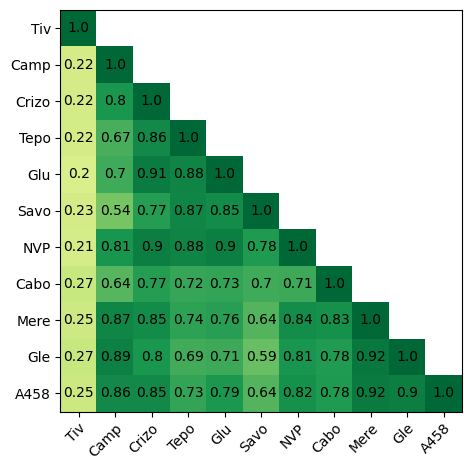

In [297]:
def plot_correlation_matrix(datasets, dataset_labels):
    counts_matrix = np.zeros((len(datasets), len(datasets)))
    correlation_matrix = np.zeros((len(datasets), len(datasets)))
    correlation_matrix[:] = np.nan

    for i in range(len(datasets)):
        for j in range(i + 1):
            dataset_i = []
            dataset_j = []
            for key in datasets[i]:
                if key in datasets[j]:
                    dataset_i.append(datasets[i][key])
                    dataset_j.append(datasets[j][key])
            counts_matrix[i, j] = len(dataset_i)
            if len(dataset_i) < 2 or len(dataset_j) < 2:
                correlation_matrix[i, j] = np.nan
            else:
                correlation_matrix[i, j] = stats.pearsonr(dataset_i, dataset_j)[0].item()

    fig, ax = plt.subplots()
    im = ax.imshow(correlation_matrix, cmap="RdYlGn", vmin=-1, vmax=1)
    
    # Show all ticks and label them with the respective list entries
    ax.set_xticks(range(len(datasets)), labels=dataset_labels, rotation=45, ha="right", rotation_mode="anchor")
    ax.set_yticks(range(len(datasets)), labels=dataset_labels)
    
    # Loop over data dimensions and create text annotations.
    for i in range(len(datasets)):
        for j in range(i + 1):
            text = ax.text(j, i, f"{round(correlation_matrix[i, j], 2)}", ha="center", va="center", color="black")
    
    # ax.set_title("Harvest of local farmers (in tons/year)")
    fig.tight_layout()
    plt.show()

plot_correlation_matrix(MET_WT_datasets, MET_ligands)

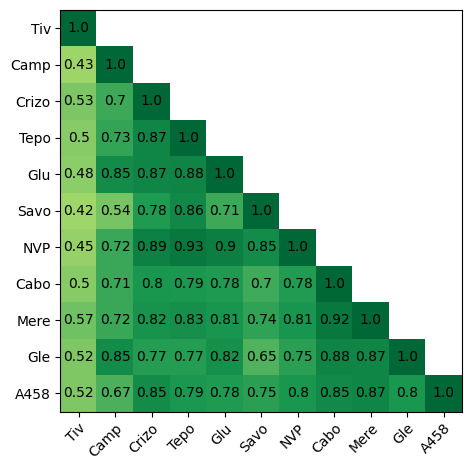

In [298]:
plot_correlation_matrix(MET_dEx14_datasets, MET_ligands)

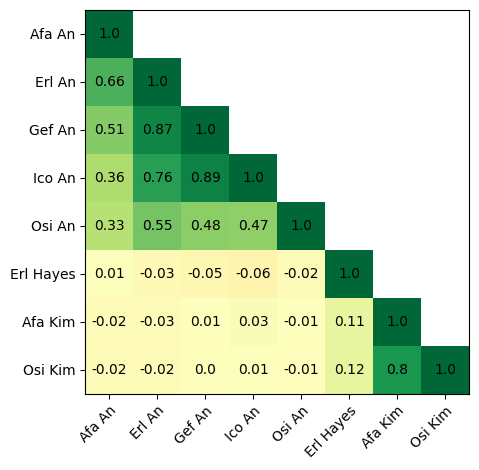

In [299]:
plot_correlation_matrix(EGFR_datasets, EGFR_ligands)

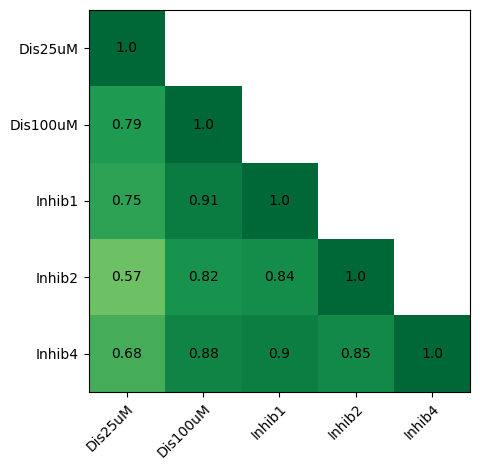

In [300]:
plot_correlation_matrix(SRC_datasets, SRC_ligands)

In [301]:
# Repeat with tails
cdk4_persky_tail = load_scores("CDK4_Persky_2020_tail.csv", directory=difference_tail_dir)
cdk6_persky_tail = load_scores("CDK6_Persky_2020_tail.csv", directory=difference_tail_dir)
EGFR_An_tail = load_scores("EGFR_An_2022_tail.csv", directory=difference_tail_dir)
EGFR_Hayes_tail = load_scores("EGFR_Hayes_2024_tail.csv", directory=difference_tail_dir)
EGFR_Kim_tail = load_scores("EGFR_Kim_2024_tail.csv", directory=difference_tail_dir)
MET_dEx14_Estevam_tail = load_scores("MET_Estevam_2024_dEx14_tail.csv", directory=difference_tail_dir)
MET_WT_Estevam_tail = load_scores("MET_Estevam_2024_WT_tail.csv", directory=difference_tail_dir)
SRC_Chakraborty_tail = load_scores("SRC_Chakraborty_2024_tail.csv", directory=difference_tail_dir)

In [302]:
CDK4_Pal_persky_tail = extract_ligand(cdk4_persky_tail, "CDK4", "Pal_2uM")

CDK6_Pal_persky_tail = extract_ligand(cdk6_persky_tail, "CDK6", "Pal_2uM")

EGFR_Afa_An_tail = extract_ligand(EGFR_An_tail, "EGFR", "Afa_50nM")
EGFR_Erl_An_tail = extract_ligand(EGFR_An_tail, "EGFR", "Erl_600nM")
EGFR_Gef_An_tail = extract_ligand(EGFR_An_tail, "EGFR", "Gef_600nM")
EGFR_Ico_An_tail = extract_ligand(EGFR_An_tail, "EGFR", "Ico_600nM")
EGFR_Osi_An_tail = extract_ligand(EGFR_An_tail, "EGFR", "Osi_200nM")

EGFR_Erl_Hayes_tail = extract_ligand(EGFR_Hayes_tail, "EGFR", "Erl_200nM")

EGFR_Afa_Kim_tail = extract_ligand(EGFR_Kim_tail, "EGFR", "Afa_3nM")
EGFR_Osi_Kim_tail = extract_ligand(EGFR_Kim_tail, "EGFR", "Osi_8nM")

EGFR_T790M_Osi_Kim_tail = extract_ligand(EGFR_Kim_tail, "EGFR_T790M", "Osi_8nM")

MET_dEx14_Savo_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "Savo_1.51nM")
MET_dEx14_NVP_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "NVP_45.1nM")
MET_dEx14_Tiv_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "Tiv_2.55uM")
MET_dEx14_Camp_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "Camp_6.70nM")
MET_dEx14_A458_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "A458_534nM")
MET_dEx14_Cabo_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "Cabo_71nM")
MET_dEx14_Gle_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "Gle_324nM")
MET_dEx14_Crizo_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "Crizo_21.9nM")
MET_dEx14_Glu_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "Glu_31.3nM")
MET_dEx14_Mere_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "Mere_47.3nM")
MET_dEx14_Tepo_Estevam_tail = extract_ligand(MET_dEx14_Estevam_tail, "MET_dEx14", "Tepo_1.74nM")

MET_WT_Savo_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "Savo_1.51nM")
MET_WT_NVP_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "NVP_45.1nM")
MET_WT_Tiv_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "Tiv_2.55uM")
MET_WT_Camp_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "Camp_6.70nM")
MET_WT_A458_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "A458_534nM")
MET_WT_Cabo_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "Cabo_71nM")
MET_WT_Gle_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "Gle_324nM")
MET_WT_Crizo_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "Crizo_21.9nM")
MET_WT_Glu_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "Glu_31.3nM")
MET_WT_Mere_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "Mere_47.3nM")
MET_WT_Tepo_Estevam_tail = extract_ligand(MET_WT_Estevam_tail, "MET_WT", "Tepo_1.74nM")

SRC_Dis25uM_Chakraborty_tail = extract_ligand(SRC_Chakraborty_tail, "SRC", "Dis_25uM")
SRC_Dis100uM_Chakraborty_tail = extract_ligand(SRC_Chakraborty_tail, "SRC", "Dis_100uM")
SRC_Inhib1_Chakraborty_tail = extract_ligand(SRC_Chakraborty_tail, "SRC", "Inhib1_8uM")
SRC_Inhib2_Chakraborty_tail = extract_ligand(SRC_Chakraborty_tail, "SRC", "Inhib2_2uM")
SRC_Inhib4_Chakraborty_tail = extract_ligand(SRC_Chakraborty_tail, "SRC", "Inhib4_0.8uM")

In [303]:
MET_WT_tail_datasets = [MET_WT_Tiv_Estevam_tail, MET_WT_Camp_Estevam_tail, 
                        MET_WT_Crizo_Estevam_tail, MET_WT_Tepo_Estevam_tail, 
                        MET_WT_Glu_Estevam_tail, MET_WT_Savo_Estevam_tail, 
                        MET_WT_NVP_Estevam_tail, MET_WT_Cabo_Estevam_tail, 
                        MET_WT_Mere_Estevam_tail, MET_WT_Gle_Estevam_tail, 
                        MET_WT_A458_Estevam_tail]
MET_dEx14_tail_datasets = [MET_dEx14_Tiv_Estevam_tail, MET_dEx14_Camp_Estevam_tail, 
                           MET_dEx14_Crizo_Estevam_tail, MET_dEx14_Tepo_Estevam_tail, 
                           MET_dEx14_Glu_Estevam_tail, MET_dEx14_Savo_Estevam_tail, 
                           MET_dEx14_NVP_Estevam_tail, MET_dEx14_Cabo_Estevam_tail, 
                           MET_dEx14_Mere_Estevam_tail, MET_dEx14_Gle_Estevam_tail, 
                           MET_dEx14_A458_Estevam_tail]
EGFR_tail_datasets = [EGFR_Afa_An_tail, EGFR_Erl_An_tail, EGFR_Gef_An_tail, 
                      EGFR_Ico_An_tail, EGFR_Osi_An_tail, EGFR_Erl_Hayes_tail, 
                      EGFR_Afa_Kim_tail, EGFR_Osi_Kim_tail]
SRC_tail_datasets = [SRC_Dis25uM_Chakraborty_tail, SRC_Dis100uM_Chakraborty_tail, 
                     SRC_Inhib1_Chakraborty_tail, SRC_Inhib2_Chakraborty_tail, 
                     SRC_Inhib4_Chakraborty_tail]

MET_ligands = ["Tiv", "Camp", "Crizo", "Tepo", "Glu", "Savo", "NVP", "Cabo",
               "Mere", "Gle", "A458"]
EGFR_ligands = ["Afa_An", "Erl_An", "Gef_An", "Ico_An", "Osi_An", "Erl_Hayes",
                "Afa_Kim", "Osi_Kim"]
SRC_ligands = ["Dis25uM", "Dis100uM", "Inhib1", "Inhib2", "Inhib4"]

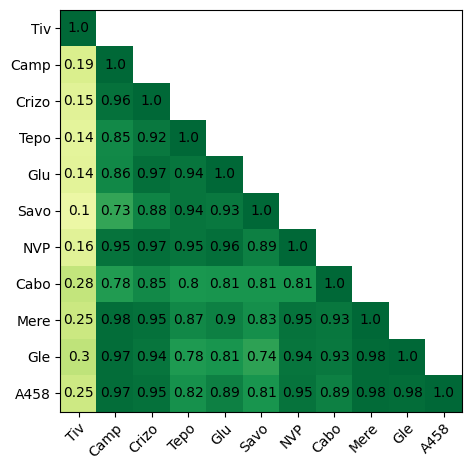

In [304]:
plot_correlation_matrix(MET_WT_tail_datasets, MET_ligands)

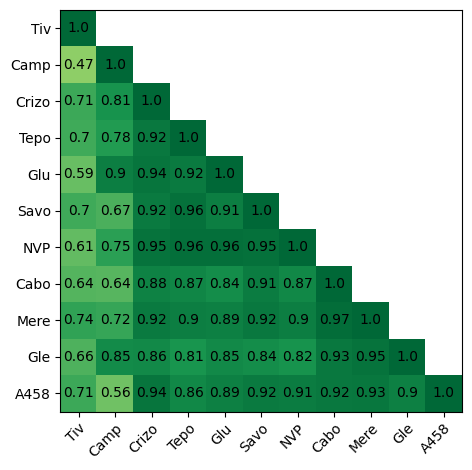

In [305]:
plot_correlation_matrix(MET_dEx14_tail_datasets, MET_ligands)

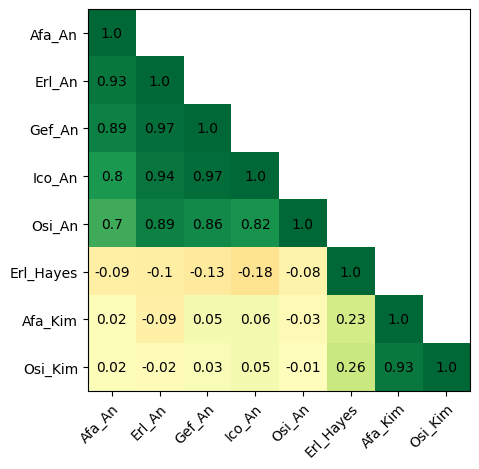

In [306]:
plot_correlation_matrix(EGFR_tail_datasets, EGFR_ligands)

In [322]:
# Generate scatter plots of mutation scores to assess correlation

def scatter_scores(dataset_i, dataset_j, dataset_i_label, dataset_j_label, size):
    scores_i = []
    scores_j = []
    for key in dataset_i:
        if key in dataset_j:
            scores_i.append(dataset_i[key])
            scores_j.append(dataset_j[key])

    fig, axs = plt.subplots()
    axs.scatter(scores_i, scores_j, s=size)
    axs.set_xlabel(dataset_i_label)
    axs.set_ylabel(dataset_j_label)

    fig.tight_layout()
    fig.set_figwidth(4.5)EGFR_datasets[0]
    fig.set_figheight(6)

    plt.show()

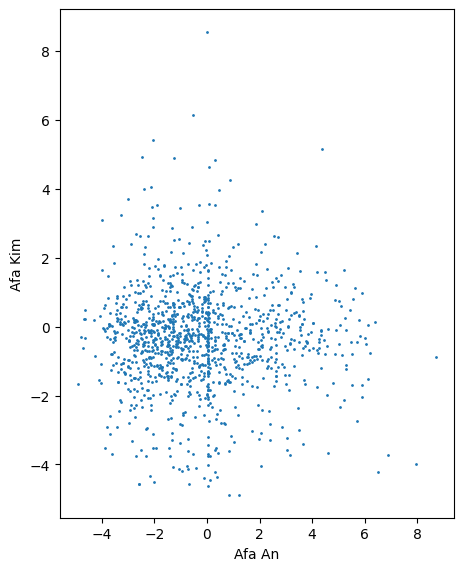

In [323]:
scatter_scores(EGFR_datasets[0], EGFR_datasets[6], "Afa An", "Afa Kim", 1)

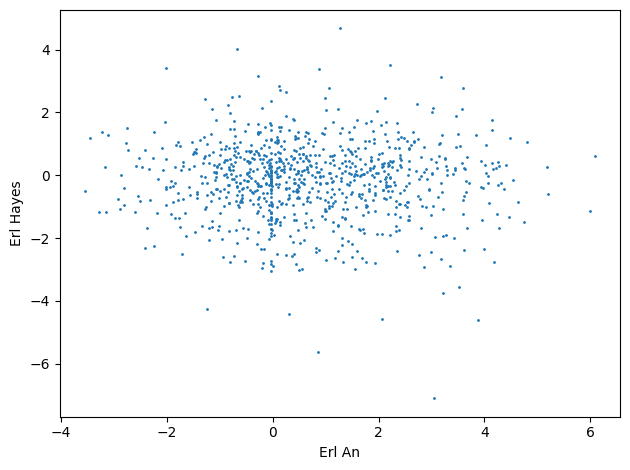

In [309]:
scatter_scores(EGFR_datasets[1], EGFR_datasets[5], "Erl An", "Erl Hayes", 1)

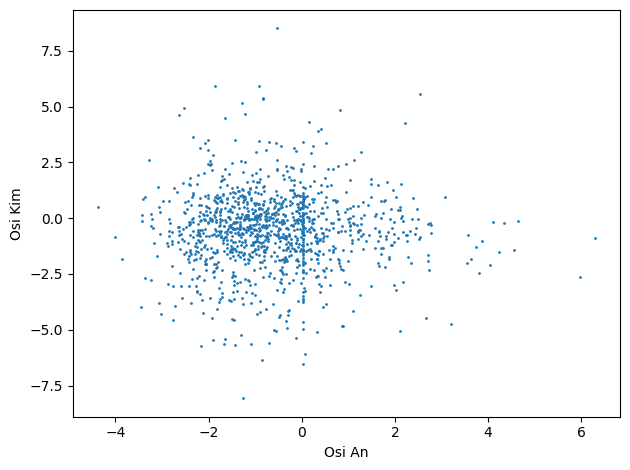

In [310]:
scatter_scores(EGFR_datasets[4], EGFR_datasets[7], "Osi An", "Osi Kim", 1)

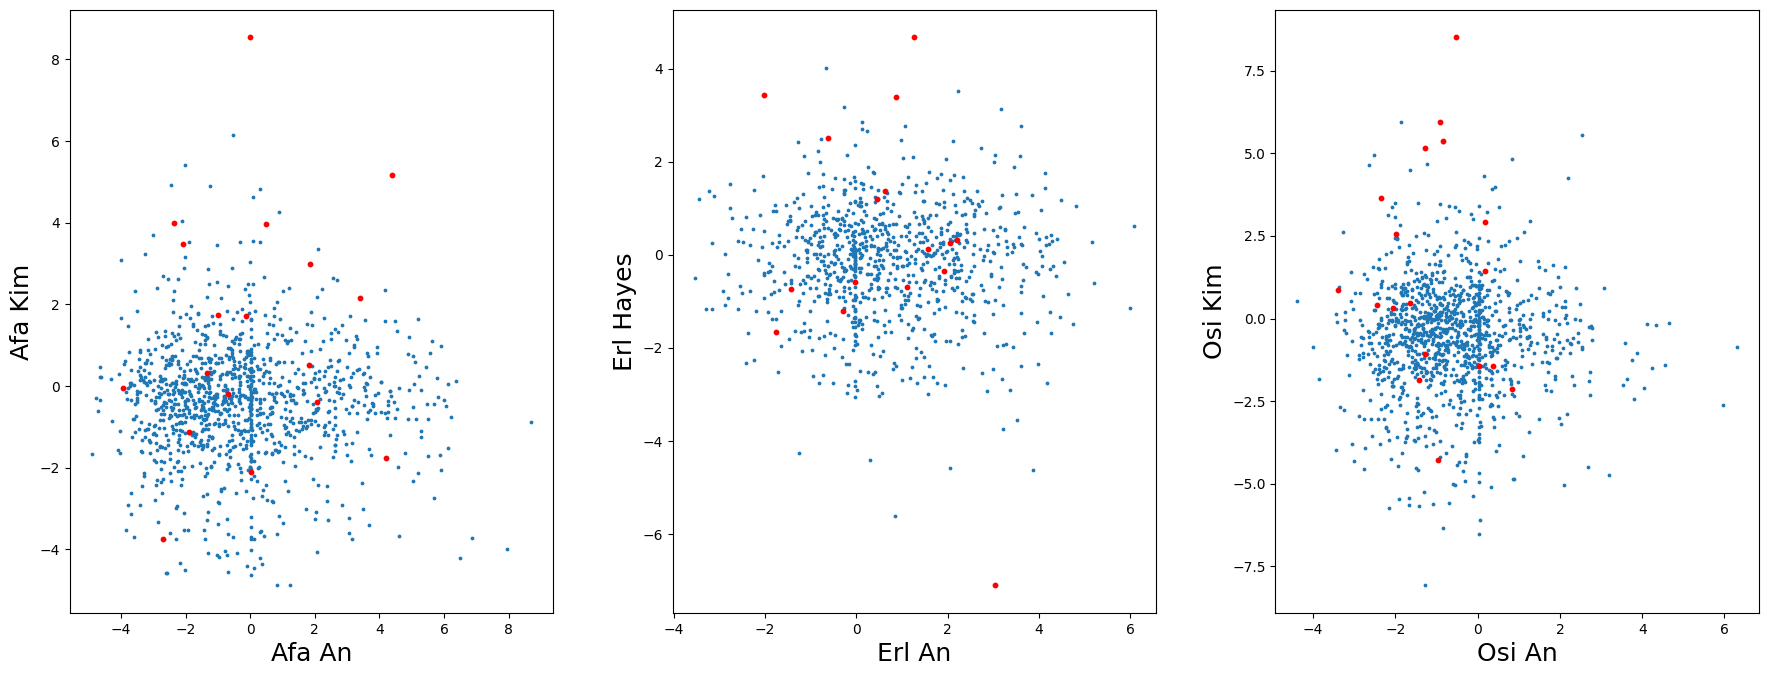

In [432]:
# Narrow to analyzing variants of known significance

vks = [('R', 108, 'K'), ('M', 277, 'E'), ('A', 289, 'V'), ('G', 598, 'V'), 
       ('E', 709, 'A'), ('G', 719, 'A'), ('L', 747, 'P'), ('S', 768, 'I'), 
       ('G', 779, 'F'), ('L', 858, 'R'), ('L', 861, 'K'), ('S', 678, 'N'), 
       ('S', 678, 'I'), ('G', 719, 'A'), ('G', 719, 'S'), ('T', 790, 'M'), 
       ('C', 797, 'S'), ('R', 831, 'H'), ('L', 858, 'R'), ('L', 861, 'Q'), 
       ('L', 718, 'V'), ('L', 718, 'Q'), ('T', 725, 'M'), ('T', 725, 'R'), 
       ('S', 752, 'C'), ('K', 754, 'I'), ('L', 777, 'M'), ('L', 792, 'F'),
       ('L', 792, 'H'), ('C', 797, 'S'), ('C', 797, 'G'), ('T', 854, 'A')]

datasets = [(EGFR_datasets[0], EGFR_datasets[6]), 
            (EGFR_datasets[1], EGFR_datasets[5]), 
            (EGFR_datasets[4], EGFR_datasets[7])]
dataset_labels = [("Afa An", "Afa Kim"), ("Erl An", "Erl Hayes"), ("Osi An", "Osi Kim")]

fig, axs = plt.subplots(1, 3)
for i in range(3):
    scores_i = []
    scores_j = []
    for key in datasets[i][0]:
        if key in datasets[i][1]:
            scores_i.append(datasets[i][0][key])
            scores_j.append(datasets[i][1][key])
    
    scores_i_vks = []
    scores_j_vks = []
    for key in datasets[i][0]:
        if key in datasets[i][1] and key in vks:
            scores_i_vks.append(datasets[i][0][key])
            scores_j_vks.append(datasets[i][1][key])
    axs[i].scatter(scores_i, scores_j, s=3)
    axs[i].scatter(scores_i_vks, scores_j_vks, s=10, color='red')
    axs[i].set_xlabel(dataset_labels[i][0], fontsize=18)
    axs[i].set_ylabel(dataset_labels[i][1], fontsize=18)

fig.tight_layout(pad=-2)
fig.set_figwidth(17)
fig.set_figheight(6)
plt.show()

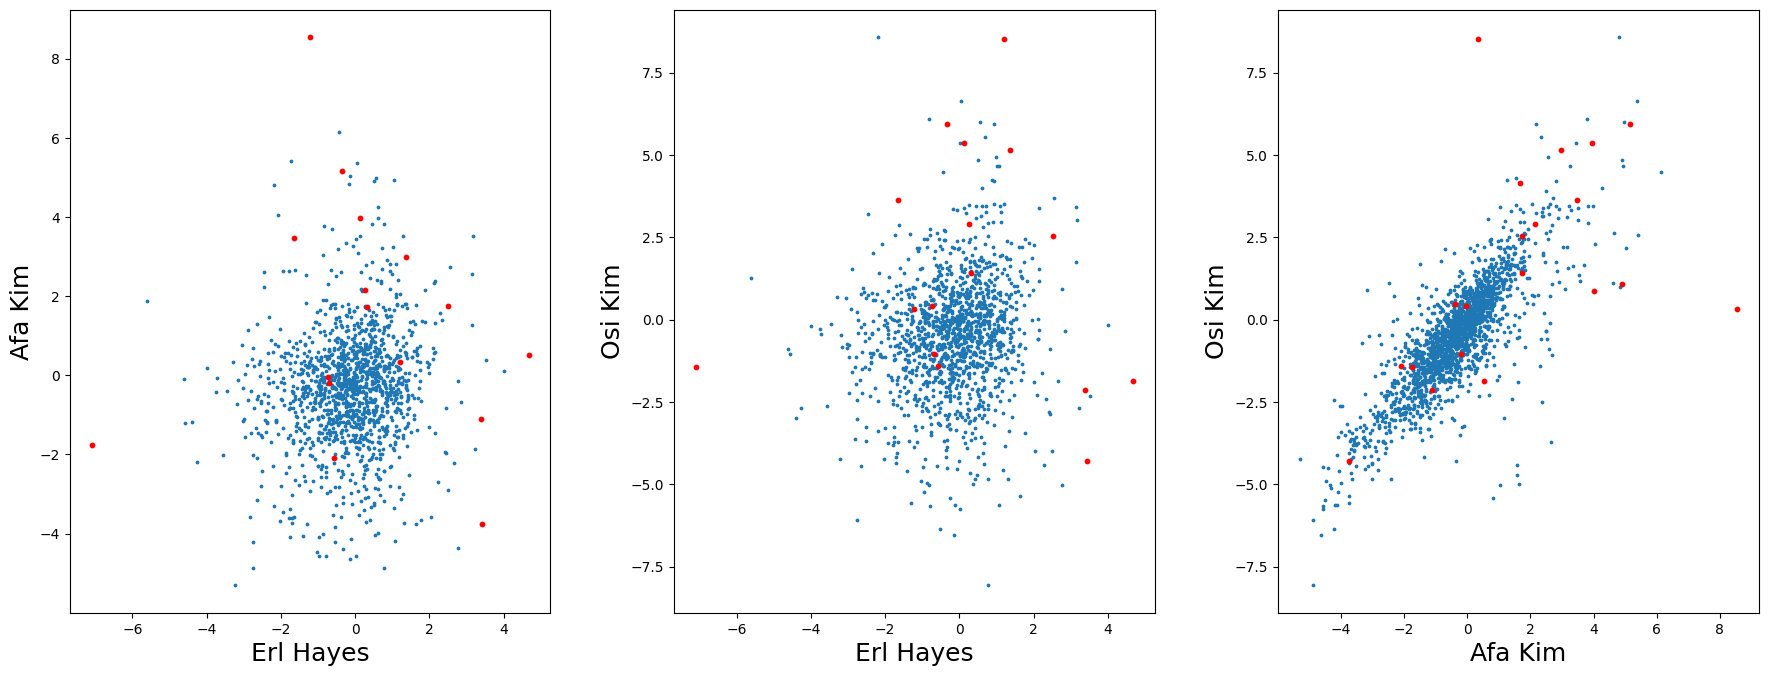

In [433]:
vks = [('R', 108, 'K'), ('M', 277, 'E'), ('A', 289, 'V'), ('G', 598, 'V'), 
       ('E', 709, 'A'), ('G', 719, 'A'), ('L', 747, 'P'), ('S', 768, 'I'), 
       ('G', 779, 'F'), ('L', 858, 'R'), ('L', 861, 'K'), ('S', 678, 'N'), 
       ('S', 678, 'I'), ('G', 719, 'A'), ('G', 719, 'S'), ('T', 790, 'M'), 
       ('C', 797, 'S'), ('R', 831, 'H'), ('L', 858, 'R'), ('L', 861, 'Q'), 
       ('L', 718, 'V'), ('L', 718, 'Q'), ('T', 725, 'M'), ('T', 725, 'R'), 
       ('S', 752, 'C'), ('K', 754, 'I'), ('L', 777, 'M'), ('L', 792, 'F'),
       ('L', 792, 'H'), ('C', 797, 'S'), ('C', 797, 'G'), ('T', 854, 'A')]

datasets = [(EGFR_datasets[5], EGFR_datasets[6]), 
            (EGFR_datasets[5], EGFR_datasets[7]), 
            (EGFR_datasets[6], EGFR_datasets[7])]
dataset_labels = [("Erl Hayes", "Afa Kim"), ("Erl Hayes", "Osi Kim"), ("Afa Kim", "Osi Kim")]

fig, axs = plt.subplots(1, 3)
for i in range(3):
    scores_i = []
    scores_j = []
    for key in datasets[i][0]:
        if key in datasets[i][1]:
            scores_i.append(datasets[i][0][key])
            scores_j.append(datasets[i][1][key])
    
    scores_i_vks = []
    scores_j_vks = []
    for key in datasets[i][0]:
        if key in datasets[i][1] and key in vks:
            scores_i_vks.append(datasets[i][0][key])
            scores_j_vks.append(datasets[i][1][key])
    axs[i].scatter(scores_i, scores_j, s=3)
    axs[i].scatter(scores_i_vks, scores_j_vks, s=10, color='red')
    axs[i].set_xlabel(dataset_labels[i][0], fontsize=18)
    axs[i].set_ylabel(dataset_labels[i][1], fontsize=18)

fig.tight_layout(pad=-2)
fig.set_figwidth(17)
fig.set_figheight(6)
plt.show()

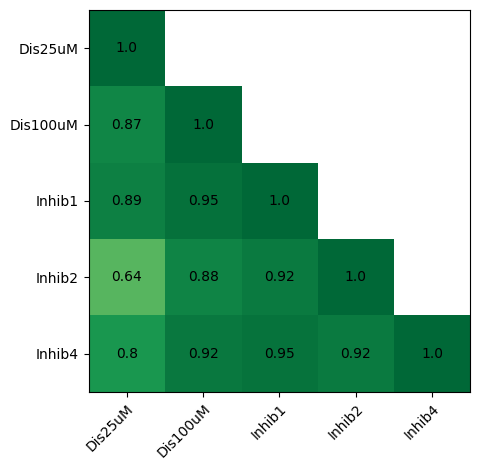

In [126]:
plot_correlation_matrix(SRC_tail_datasets, SRC_ligands)

## Dig into EGFR Raw Datasets to verify correlations

In [231]:
main_dir = Path("/Users/isaiahhazelwood/Documents/rotations-2024/fraser-lab/DMS-data/")
raw_data_dir = main_dir / "raw-data/"
difference_dir = main_dir / "diff-scores/"
difference_tail_dir = main_dir / "diff-tail-scores/"

def load_raw_data(filename, keep_cols, header=0, directory=raw_data_dir, sep=","):
    """
    Load a given set of columns from a csv file as string lists.
    filename: file name within the raw-data directory
    keep_cols: 0-indexed list of columns to record
    header: number of header lines to skip
    """
    loaded = [[] for _ in keep_cols] # List of data points in that column
    with open(directory / filename, "r") as f_raw:
        for line_num, line in enumerate(f_raw):
            if line_num < header: # Skip lines in header
                continue
            cols = line.rstrip("\n").split(sep)
            for data_i, col_i in enumerate(keep_cols):
                loaded[data_i].append(cols[col_i])
    return loaded

SINGLE_AA = ['C', 'D', 'S', 'Q', 'K', 'I', 'P', 'T', 'F', 'N', 'G', 'H', 'L',
             'R', 'W', 'A', 'V', 'E', 'Y', 'M', '*']
aa3to1 = {'CYS': 'C', 'ASP': 'D', 'SER': 'S', 'GLN': 'Q', 'LYS': 'K',
          'ILE': 'I', 'PRO': 'P', 'THR': 'T', 'PHE': 'F', 'ASN': 'N', 
          'GLY': 'G', 'HIS': 'H', 'LEU': 'L', 'ARG': 'R', 'TRP': 'W', 
          'ALA': 'A', 'VAL': 'V', 'GLU': 'E', 'TYR': 'Y', 'MET': 'M', 'TER': '*'}

### Load Hayes raw scores (optionally normalize by minor mutations)

In [256]:
# Load control data from the Chakraborty 2019 EGFR DMS paper
with open(raw_data_dir / "EGFR-Chakraborty-2019.html", 'r') as f_chakraborty_2019:
    raw_chakraborty_2019 = f_chakraborty_2019.readlines()
chakraborty_records = raw_chakraborty_2019[0].rstrip("\n").split(",")
chakraborty_control = {}
for record in chakraborty_records:
    fields = record.split("<\\/br>")
    snv = fields[0].split()[1]
    wt = snv[0]
    pos = snv[1:-1]
    if pos == "":
        continue
    mut = snv[-1]
    fc = float(fields[1].split()[1])
    chakraborty_control[(wt, int(pos), mut)] = np.log2(fc + 0.0001)

# Load Hayes 2024 EGFR scores
egfr_hayes_data = load_raw_data("EGFR-Hayes-2024-all.csv", (0, 2), header=1)
hayes_erl_200nM = {}
for i in range(len(egfr_hayes_data[0])):
    wt = egfr_hayes_data[0][i][:1]
    pos = egfr_hayes_data[0][i][1:-1]
    if pos == "":
        continue
    mut = egfr_hayes_data[0][i][-1:]
    hayes_erl_200nM[(wt, int(pos), mut)] = float(egfr_hayes_data[1][i])

# Plot the score distribution of minor mutations (choosing a reasonable limit to avoid outliers)
minor_aa = ('L', 'I', 'V')
chakraborty_control_minor = {key: chakraborty_control[key] for key in chakraborty_control 
                             if key[0] in minor_aa and key[2] in minor_aa and abs(chakraborty_control[key]) <= 1}
hayes_erl_200nM_minor = {key: hayes_erl_200nM[key] for key in hayes_erl_200nM 
                         if key[0] in minor_aa and key[2] in minor_aa and abs(hayes_erl_200nM[key]) <= 1}

# fig, axs = plt.subplots(1, 2)
# axs[0].hist(list(chakraborty_control_minor.values()), bins=60)
# axs[0].set_xlabel("Minor log(U/E)", size=20)
# axs[0].set_ylabel("Counts", size=20)
# axs[1].hist(list(hayes_erl_200nM_minor.values()), bins=60)
# axs[1].set_xlabel("Minor log(T/E)", size=20)
# axs[1].set_ylabel("Counts", size=20)

# fig.tight_layout(pad=-1)
# fig.set_figwidth(20)
# fig.set_figheight(10)

# chakraborty_control_minor_mean = np.mean(list(chakraborty_control_minor.values()))
# hayes_erl_200nM_minor_mean = np.mean(list(hayes_erl_200nM_minor.values()))
# print(f"Control minor mutation mean, std: {chakraborty_control_minor_mean}, {np.std(list(chakraborty_control_minor.values()))}")
# print(f"Treated mean, std: {hayes_erl_200nM_minor_mean}, {np.std(list(hayes_erl_200nM_minor.values()))}")

# Shift distributions by the mean of the minor mutation distributions
# for key in chakraborty_control:
#     chakraborty_control[key] = chakraborty_control[key] - chakraborty_control_minor_mean
# for key in hayes_erl_200nM:
#     hayes_erl_200nM[key] = hayes_erl_200nM[key] - hayes_erl_200nM_minor_mean

### Load An raw scores (optionally normalize by minor mutations)

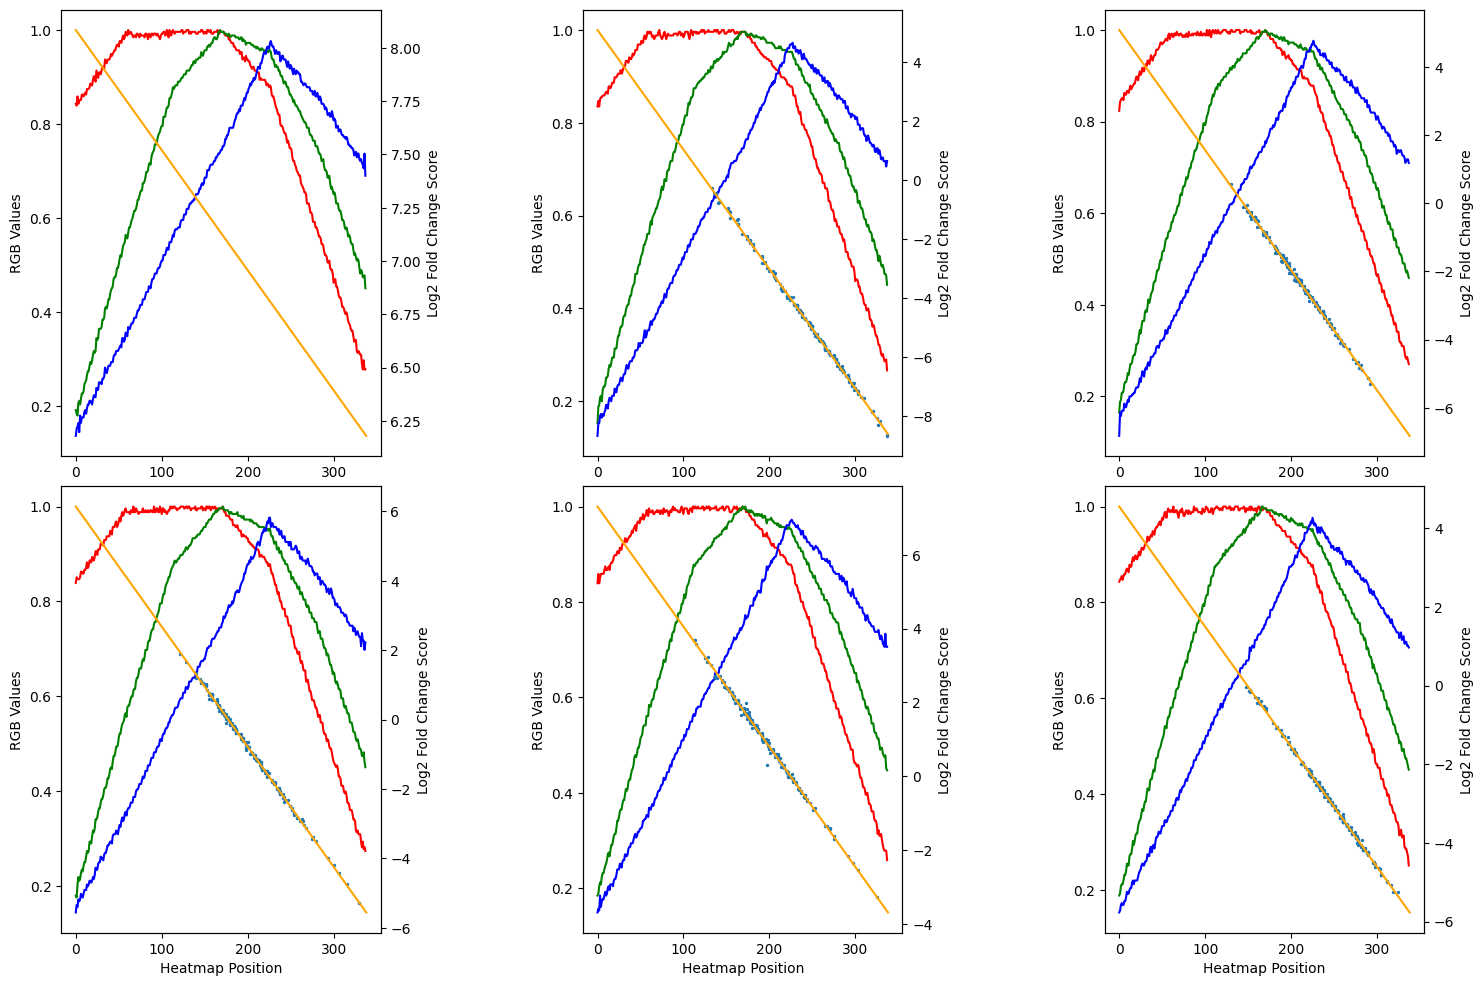

In [260]:
fig3 = np.array(Image.open(raw_data_dir / "EGFR-An-2022.jpg"))
# 645 evenly divides
fig3_panels = [np.array(fig3[(654 * i):(654 * (i+1)), :, :], dtype=np.float64) / 255.0 for i in range(6)]

row_aas = ['H', 'K', 'R', 'D', 'E', 'C', 'M', 'N', 'Q', 'S', 'T', 'A', 'I', 'L', 'V', 'F', 'W', 'Y', 'G', 'P']
aas_to_row = {aa: row for row, aa in enumerate(row_aas)}
egfr_an_sup = load_raw_data("EGFR-An-2022-SupTab5.csv", (0, 1, 2, 3, 4, 5, 6), header=1)

egfr_an_mutations = [(int(egfr_an_sup[0][i]) - 688, aas_to_row[egfr_an_sup[1][i]]) for i in range(len(egfr_an_sup))]
egfr_an_mutation_scores_all_panel = []
egfr_an_mutation_heatmap_i_all_panel = []
for panel_i, panel in enumerate(fig3_panels[1:]):
    egfr_an_mutation_scores = []
    egfr_an_mutation_heatmap_i = []
    heatmap_colors = panel[2:340, 2450, :]
    for mutation_i in range(len(egfr_an_sup[0])):
        mutation_row = aas_to_row[egfr_an_sup[1][mutation_i]]
        mutation_col = int(egfr_an_sup[0][mutation_i]) - 688
        egfr_an_mutation_color = panel[round(13 + 20.4 * mutation_row), round(233 + 11.32 * mutation_col), :]
        mutation_heatmap_color_diff = np.sum((heatmap_colors - egfr_an_mutation_color) ** 2, axis=1)
        egfr_an_mutation_heatmap_i.append(np.argmin(mutation_heatmap_color_diff))
        egfr_an_mutation_scores.append(float(egfr_an_sup[panel_i + 2][mutation_i]))
        if np.argmin(mutation_heatmap_color_diff) < 100:
            print(f"Panel {panel_i}: mutation {egfr_an_sup[0][mutation_i]}{egfr_an_sup[1][mutation_i]} has color {255.0 * egfr_an_mutation_color}, score {float(egfr_an_sup[panel_i + 2][mutation_i])}, assigned location {np.argmin(mutation_heatmap_color_diff)}")
    egfr_an_mutation_scores_all_panel.append(egfr_an_mutation_scores)
    egfr_an_mutation_heatmap_i_all_panel.append(egfr_an_mutation_heatmap_i)

# Plot colors in color bar
egfr_an_heatmap_score_params = [(-0.005630516384295408, 8.08331642487572)] # control slope calculated manually
fig, axs = plt.subplots(2, 3)
for i, panel in enumerate(fig3_panels):
    # Plot the RGB values
    axs[i // 3, i % 3].plot(panel[2:340, 2450, 0], color='r')
    axs[i // 3, i % 3].plot(panel[2:340, 2450, 1], color='g')
    axs[i // 3, i % 3].plot(panel[2:340, 2450, 2], color='b')
    axs[i // 3, i % 3].set_xlabel("Heatmap Position")
    axs[i // 3, i % 3].set_ylabel("RGB Values")

    # Plot the supplemental scores if known and the interpolated heatmap
    axs_scatter = axs[i // 3, i % 3].twinx()
    if (i > 0):
        axs_scatter.scatter(egfr_an_mutation_heatmap_i_all_panel[i - 1], egfr_an_mutation_scores_all_panel[i - 1], s=2)
        m, b = np.polyfit(egfr_an_mutation_heatmap_i_all_panel[i - 1], egfr_an_mutation_scores_all_panel[i - 1], deg=1)
        egfr_an_heatmap_score_params.append((m, b))
    m, b = egfr_an_heatmap_score_params[-1]
    axs_scatter.plot([m * i + b for i in range(339)], color='orange')
    axs_scatter.set_ylabel("Log2 Fold Change Score")

fig.tight_layout(pad=-2)
fig.set_figwidth(15)
fig.set_figheight(9)

an_scores_by_treatment = []
for panel_i, panel in enumerate(fig3_panels):
    scores = {}
    m, b = egfr_an_heatmap_score_params[panel_i]
    heatmap_colors = panel[2:340, 2450, :]
    for row in range(20):
        for col in range(188):
            mutation_color = panel[round(13 + 20.4 * row), round(233 + 11.32 * col), :]
            mutation_heatmap_color_diff = np.sum((heatmap_colors - mutation_color) ** 2, axis=1)
            if np.min(mutation_heatmap_color_diff) > 0.05:
                print(f"Warning: bad match in {panel_i}, {row_aas[row]}, {col}")
            mutation_heatmap_i = np.argmin(mutation_heatmap_color_diff)
            mutation_score = m * mutation_heatmap_i + b
            scores[(col + 687, row_aas[row])] = mutation_score
    an_scores_by_treatment.append(scores)

# Plot distribution of minor mutations
# minor_aa = ('L', 'I', 'V')
# egfr_seq = "MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFEDHFLSLQRMFNNCEVVLGNLEITYVQRNYDLSFLKTIQEVAGYVLIALNTVERIPLENLQIIRGNMYYENSYALAVLSNYDANKTGLKELPMRNLQEILHGAVRFSNNPALCNVESIQWRDIVSSDFLSNMSMDFQNHLGSCQKCDPSCPNGSCWGAGEENCQKLTKIICAQQCSGRCRGKSPSDCCHNQCAAGCTGPRESDCLVCRKFRDEATCKDTCPPLMLYNPTTYQMDVNPEGKYSFGATCVKKCPRNYVVTDHGSCVRACGADSYEMEEDGVRKCKKCEGPCRKVCNGIGIGEFKDSLSINATNIKHFKNCTSISGDLHILPVAFRGDSFTHTPPLDPQELDILKTVKEITGFLLIQAWPENRTDLHAFENLEIIRGRTKQHGQFSLAVVSLNITSLGLRSLKEISDGDVIISGNKNLCYANTINWKKLFGTSGQKTKIISNRGENSCKATGQVCHALCSPEGCWGPEPRDCVSCRNVSRGRECVDKCNLLEGEPREFVENSECIQCHPECLPQAMNITCTGRGPDNCIQCAHYIDGPHCVKTCPAGVMGENNTLVWKYADAGHVCHLCHPNCTYGCTGPGLEGCPTNGPKIPSIATGMVGALLLLLVVALGIGLFMRRRHIVRKRTLRRLLQERELVEPLTPSGEAPNQALLRILKETEFKKIKVLGSGAFGTVYKGLWIPEGEKVKIPVAIKELREATSPKANKEILDEAYVMASVDNPHVCRLLGICLTSTVQLITQLMPFGCLLDYVREHKDNIGSQYLLNWCVQIAKGMNYLEDRRLVHRDLAARNVLVKTPQHVKITDFGLAKLLGAEEKEYHAEGGKVPIKWMALESILHRIYTHQSDVWSYGVTVWELMTFGSKPYDGIPASEISSILEKGERLPQPPICTIDVYMIMVKCWMIDADSRPKFRELIIEFSKMARDPQRYLVIQGDERMHLPSPTDSNFYRALMDEEDMDDVVDADEYLIPQQGFFSSPSTSRTPLLSSLSATSNNSTVACIDRNGLQSCPIKEDSFLQRYSSDPTGALTEDSIDDTFLPVPEYINQSVPKRPAGSVQNPVYHNQPLNPAPSRDPHYQDPHSTAVGNPEYLNTVQPTCVNSTFDSPAHWAQKGSHQISLDNPDYQQDFFPKEAKPNGIFKGSTAENAEYLRVAPQSSEFIGA"
# minor_ranges = ((6.6, 7.2), (-8, 0), (-4.5, -0.5), (-2, -0.5), (-1, 1), (-2, -1.5))

# minor_mutation_means = []
# fig, axs = plt.subplots(2, 3)
# for i in range(len(an_scores_by_treatment)):
#     minor_mutation_scores = [an_scores_by_treatment[i][key] for key in an_scores_by_treatment[i] if egfr_seq[key[0] - 1] in minor_aa and key[1] in minor_aa]
#     axs[i // 3, i % 3].hist(list(minor_mutation_scores), bins=60)
#     if i == 0:
#         axs[i // 3, i % 3].set_xlabel("Minor log U/E", size=20)
#     else:
#         axs[i // 3, i % 3].set_xlabel("Minor log T/E", size=20)
#     axs[i // 3, i % 3].set_ylabel("Counts", size=20)

#     minor_mutation_means.append(np.mean([score for score in minor_mutation_scores if minor_ranges[i][0] < score < minor_ranges[i][1]]))
#     print(f"Panel {i} mean: {minor_mutation_means[-1]}")

# fig.tight_layout(pad=-1)
# fig.set_figwidth(20)
# fig.set_figheight(10)

# Normalize scores by WT
# minor_mutation_means = (6.90, -3.77, -2.27, -1.23, 0.29, -1.87)
# for i in range(len(an_scores_by_treatment)):
#     for key in an_scores_by_treatment[i]:
#         an_scores_by_treatment[i][key] = an_scores_by_treatment[i][key] - minor_mutation_means[i]

for i in range(len(an_scores_by_treatment)):
    an_scores_by_treatment[i] = {(egfr_seq[pos - 1], pos, mut): an_scores_by_treatment[i][(pos, mut)] 
                                 for pos, mut in an_scores_by_treatment[i]}

### Load Kim raw scores (optionally normalize by minor mutations)

In [258]:
egfr_kim_data = load_raw_data("EGFR-Kim-2024.csv", (5, 8, 10, 12), header=2)
aa_from = []
position = []
aa_to = []

afa_scores = {}
osi_scores = {}
osi_T970M_scores = {}
for i in range(len(egfr_kim_data[0])):
    wt = egfr_kim_data[0][i][:1]
    pos = egfr_kim_data[0][i][1:-1]
    mut = egfr_kim_data[0][i][-1:]
    if egfr_kim_data[1][i] != "" and egfr_kim_data[1][i] != "N/A":
        afa_scores[(wt, int(pos), mut)] = float(egfr_kim_data[1][i])
    if egfr_kim_data[2][i] != "" and egfr_kim_data[2][i] != "N/A":
        osi_scores[(wt, int(pos), mut)] = float(egfr_kim_data[2][i])
    if egfr_kim_data[3][i] != "" and egfr_kim_data[3][i] != "N/A":
        osi_T970M_scores[(wt, int(pos), mut)] = float(egfr_kim_data[3][i])

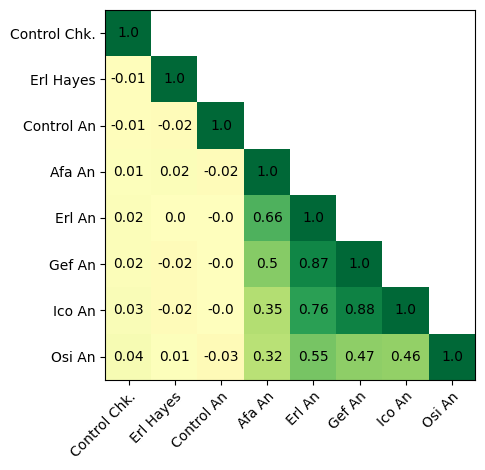

In [270]:
egfr_datasets = [chakraborty_control, hayes_erl_200nM, an_scores_by_treatment[0], an_scores_by_treatment[1],
                an_scores_by_treatment[2], an_scores_by_treatment[3], 
                an_scores_by_treatment[4], an_scores_by_treatment[5]]
egfr_datasets_labels = ["Control Chk.", "Erl Hayes", "Control An", "Afa An", "Erl An", "Gef An", "Ico An", "Osi An"]
plot_correlation_matrix(egfr_datasets, egfr_datasets_labels)

In [275]:
def scatter_scores(dataset_i, dataset_j, dataset_i_label, dataset_j_label, size):
    scores_i = []
    scores_j = []
    for key in dataset_i:
        if key in dataset_j:
            scores_i.append(dataset_i[key])
            scores_j.append(dataset_j[key])

    fig, axs = plt.subplots()
    axs.scatter(scores_i, scores_j, s=size)
    axs.set_xlabel(dataset_i_label)
    axs.set_ylabel(dataset_j_label)

    fig.tight_layout()
    plt.show()

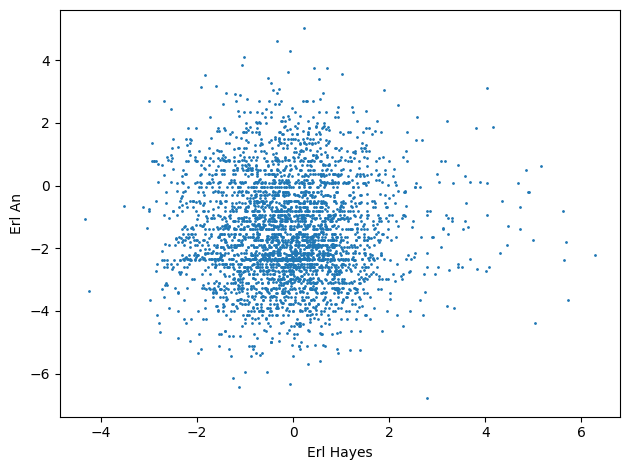

In [276]:
scatter_scores(hayes_erl_200nM, an_scores_by_treatment[2], "Erl Hayes", "Erl An", 1)

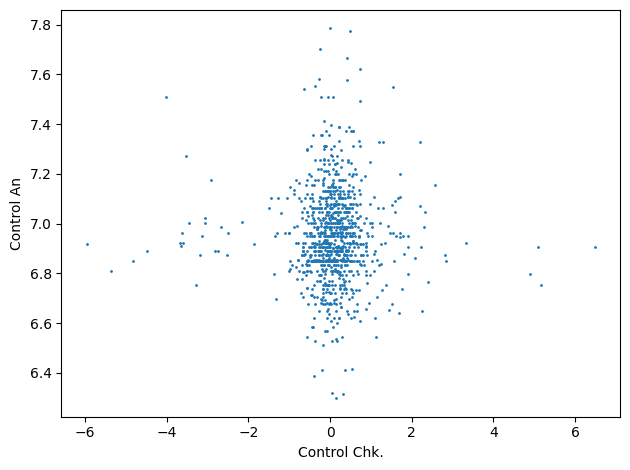

In [277]:
scatter_scores(chakraborty_control, an_scores_by_treatment[0], "Control Chk.", "Control An", 1)

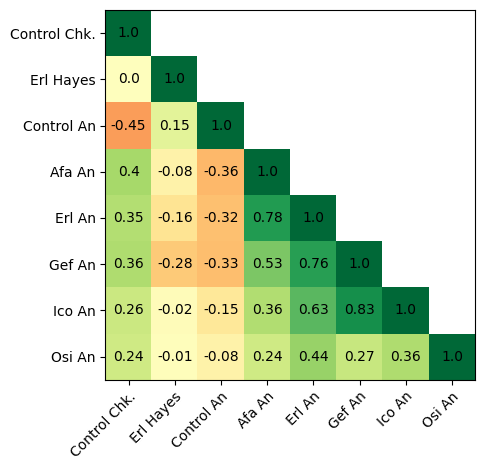

In [272]:
vks = [('R', 108, 'K'), ('M', 277, 'E'), ('A', 289, 'V'), ('G', 598, 'V'), 
       ('E', 709, 'A'), ('G', 719, 'A'), ('L', 747, 'P'), ('S', 768, 'I'), 
       ('G', 779, 'F'), ('L', 858, 'R'), ('L', 861, 'K'), ('S', 678, 'N'), 
       ('S', 678, 'I'), ('G', 719, 'A'), ('G', 719, 'S'), ('T', 790, 'M'), 
       ('C', 797, 'S'), ('R', 831, 'H'), ('L', 858, 'R'), ('L', 861, 'Q'), 
       ('L', 718, 'V'), ('L', 718, 'Q'), ('T', 725, 'M'), ('T', 725, 'R'), 
       ('S', 752, 'C'), ('K', 754, 'I'), ('L', 777, 'M'), ('L', 792, 'F'),
       ('L', 792, 'H'), ('C', 797, 'S'), ('C', 797, 'G'), ('T', 854, 'A')]

egfr_datasets_vks = [{key: dataset[key] for key in dataset if key in vks} for dataset in egfr_datasets]
plot_correlation_matrix(egfr_datasets_vks, egfr_datasets_labels)

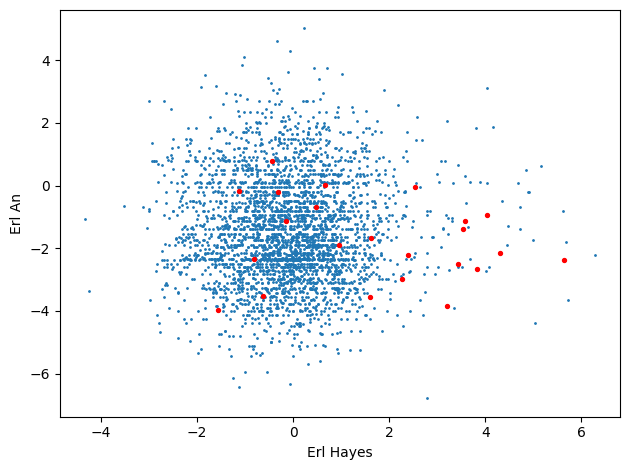

In [430]:
scores_i = []
scores_j = []
for key in egfr_datasets[1]:
    if key in egfr_datasets[4]:
        scores_i.append(egfr_datasets[1][key])
        scores_j.append(egfr_datasets[4][key])

scores_i_vks = []
scores_j_vks = []
for key in egfr_datasets_vks[1]:
    if key in egfr_datasets_vks[4]:
        scores_i_vks.append(egfr_datasets_vks[1][key])
        scores_j_vks.append(egfr_datasets_vks[4][key])

fig, axs = plt.subplots()
axs.scatter(scores_i, scores_j, s=1)
axs.scatter(scores_i_vks, scores_j_vks, s=8, color='red')
axs.set_xlabel("Erl Hayes")
axs.set_ylabel("Erl An")

fig.tight_layout()
plt.show()

# scatter_scores(egfr_datasets_vks[1], egfr_datasets_vks[4], "Erl Hayes", "Erl An", 2)

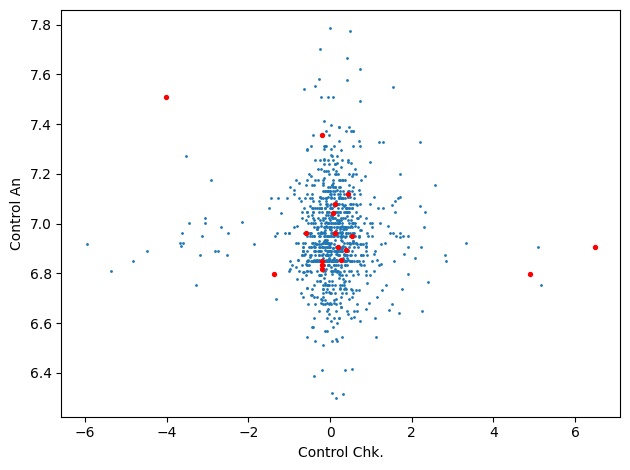

In [431]:
scores_i = []
scores_j = []
for key in egfr_datasets[0]:
    if key in egfr_datasets[2]:
        scores_i.append(egfr_datasets[0][key])
        scores_j.append(egfr_datasets[2][key])

scores_i_vks = []
scores_j_vks = []
for key in egfr_datasets_vks[0]:
    if key in egfr_datasets_vks[2]:
        scores_i_vks.append(egfr_datasets_vks[0][key])
        scores_j_vks.append(egfr_datasets_vks[2][key])

fig, axs = plt.subplots()
axs.scatter(scores_i, scores_j, s=1)
axs.scatter(scores_i_vks, scores_j_vks, s=8, color='red')
axs.set_xlabel("Control Chk.")
axs.set_ylabel("Control An")

fig.tight_layout()
plt.show()

# scatter_scores(egfr_datasets_vks[0], egfr_datasets_vks[2], "Control Chk.", "Control An", 2)

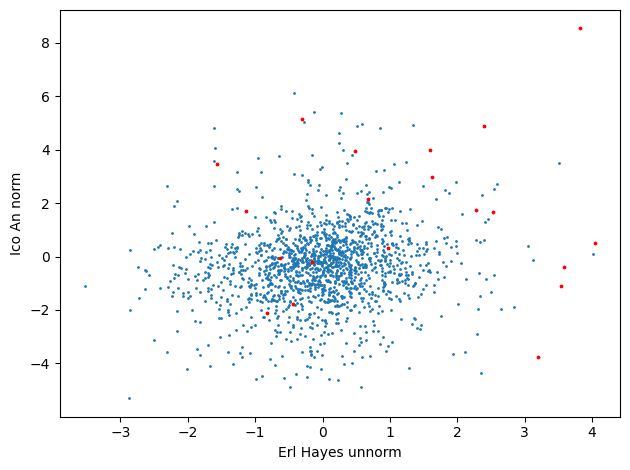

In [342]:
# Just to check: Hayes isn't already normalized by control final timepoint
scores_i = []
scores_j = []
for key in egfr_datasets[1]:
    if key in EGFR_datasets[6]:
        scores_i.append(egfr_datasets[1][key])
        scores_j.append(EGFR_datasets[6][key])

scores_i_vks = []
scores_j_vks = []
for key in egfr_datasets[1]:
    if key in EGFR_datasets[6] and key in vks:
        scores_i_vks.append(egfr_datasets[1][key])
        scores_j_vks.append(EGFR_datasets[6][key])

fig, axs = plt.subplots()
axs.scatter(scores_i, scores_j, s=1)
axs.scatter(scores_i_vks, scores_j_vks, s=3, color='red')
axs.set_xlabel("Erl Hayes unnorm")
axs.set_ylabel("Ico An norm")

fig.tight_layout()
plt.show()

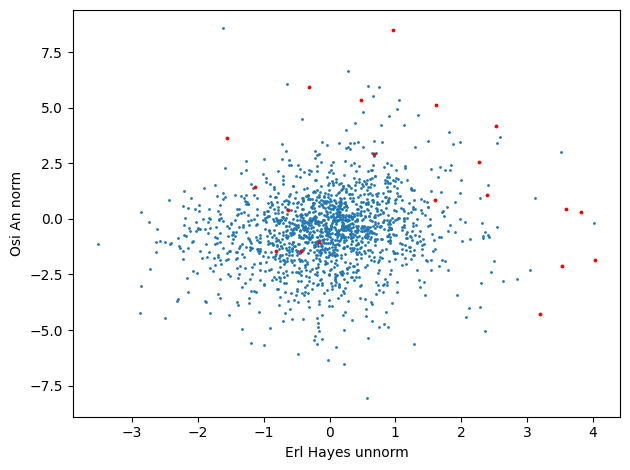

In [343]:
# Just to check: Hayes isn't already normalized by control final timepoint
scores_i = []
scores_j = []
for key in egfr_datasets[1]:
    if key in EGFR_datasets[7]:
        scores_i.append(egfr_datasets[1][key])
        scores_j.append(EGFR_datasets[7][key])

scores_i_vks = []
scores_j_vks = []
for key in egfr_datasets[1]:
    if key in EGFR_datasets[7] and key in vks:
        scores_i_vks.append(egfr_datasets[1][key])
        scores_j_vks.append(EGFR_datasets[7][key])

fig, axs = plt.subplots()
axs.scatter(scores_i, scores_j, s=1)
axs.scatter(scores_i_vks, scores_j_vks, s=3, color='red')
axs.set_xlabel("Erl Hayes unnorm")
axs.set_ylabel("Osi An norm")

fig.tight_layout()
plt.show()

## Plot frequency of each mutation in MET mutations

In [353]:
def load_scores(filename, directory=difference_dir, sep=","):
    """
    Load scores from a csv file as a dictionary of {(wt, position, mut): score}.
    filename: file name within the raw-data directory
    keep_cols: 0-indexed list of columns to record
    header: number of header lines to skip
    """
    scores = {}
    with open(directory / filename, "r") as f_scores:
        for line_num, line in enumerate(f_scores):
            if line_num < 1: # Skip header
                continue
            prot, ligand, wt, pos, mut, score = line.rstrip("\n").split(sep)
            pos = int(pos)
            score = float(score)
            scores[(prot, ligand, wt, pos, mut)] = score
    return scores

MET_WT_Estevam = load_scores("MET_Estevam_2024_WT.csv")

In [356]:
row_aas = ['H', 'K', 'R', 'D', 'E', 'C', 'M', 'N', 'Q', 'S', 'T', 'A', 'I', 'L', 'V', 'F', 'W', 'Y', 'G', 'P']
aa_to_row = {aa: row for row, aa in enumerate(row_aas)}

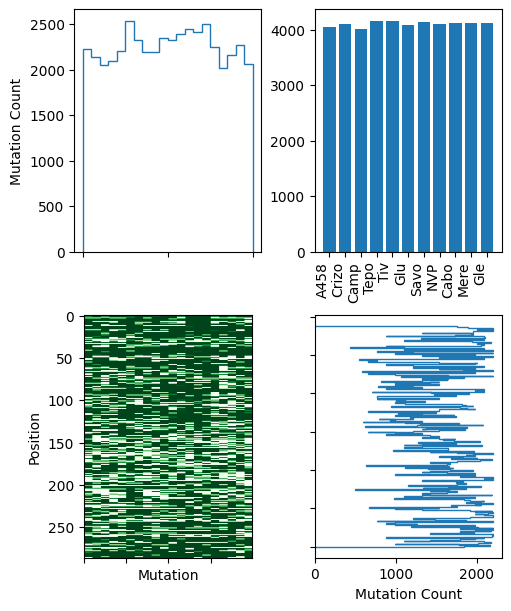

In [439]:
max_pos = max(pos for prot, ligand, wt, pos, mut in MET_WT_Estevam)
min_pos = min(pos for prot, ligand, wt, pos, mut in MET_WT_Estevam)
MET_mut_freq = np.zeros((10 * len(row_aas), max_pos - min_pos + 1))
ligand_count_dict = {}
for prot, ligand, wt, pos, mut in MET_WT_Estevam:
    for i in range(10):
        MET_mut_freq[10 * aa_to_row[mut] + i, pos - min_pos] += 1

    if ligand not in ligand_count_dict:
        ligand_count_dict[ligand] = 1
    else:
        ligand_count_dict[ligand] += 1

ligands = []
ligand_counts = []
for ligand in ligand_count_dict:
    ligands.append(ligand.split("_")[0])
    ligand_counts.append(ligand_count_dict[ligand])
    
fig, axs = plt.subplot_mosaic([["aa", "ligand"], ["mut", "pos"]], layout="constrained")
axs["mut"].imshow(MET_mut_freq.T, cmap="Greens")
axs["mut"].set_xlabel("Mutation")
axs["mut"].set_ylabel("Position")
axs["mut"].tick_params(axis="x", labelbottom=False)
axs["aa"].tick_params(axis="x", labelbottom=False)
axs["pos"].tick_params(axis="y", labelleft=False)
axs["aa"].stairs(np.sum(MET_mut_freq, axis=1))
axs["aa"].set_ylabel("Mutation Count")
axs["pos"].stairs(np.sum(MET_mut_freq, axis=0), orientation="horizontal")
axs["pos"].set_xlabel("Mutation Count")
axs["ligand"].bar(ligands, ligand_counts)
axs["ligand"].set_xticks(axs["ligand"].get_xticks(), axs["ligand"].get_xticklabels(),
                         rotation=90, ha='right')

# Show all ticks and label them with the respective list entries
# ax.set_xticks(range(len(datasets)), labels=dataset_labels, rotation=45, ha="right", rotation_mode="anchor")
# ax.set_yticks(range(len(datasets)), labels=dataset_labels)

# Loop over data dimensions and create text annotations.
# for i in range(len(datasets)):
#     for j in range(i + 1):
#         text = ax.text(j, i, f"{round(correlation_matrix[i, j], 2)}", ha="center", va="center", color="black")

fig.set_figwidth(5)
fig.set_figheight(6)

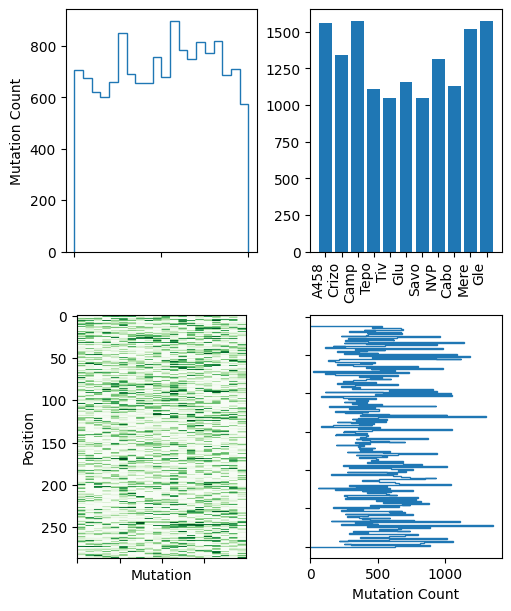

In [438]:
MET_WT_Estevam_tails = load_scores("MET_Estevam_2024_WT_tail.csv", directory = difference_tail_dir)

max_pos = max(pos for prot, ligand, wt, pos, mut in MET_WT_Estevam_tails)
min_pos = min(pos for prot, ligand, wt, pos, mut in MET_WT_Estevam_tails)
MET_mut_freq = np.zeros((10 * len(row_aas), max_pos - min_pos + 1))
ligand_count_dict = {}
for prot, ligand, wt, pos, mut in MET_WT_Estevam_tails:
    for i in range(10):
        MET_mut_freq[10 * aa_to_row[mut] + i, pos - min_pos] += 1

    if ligand not in ligand_count_dict:
        ligand_count_dict[ligand] = 1
    else:
        ligand_count_dict[ligand] += 1

ligands = []
ligand_counts = []
for ligand in ligand_count_dict:
    ligands.append(ligand.split("_")[0])
    ligand_counts.append(ligand_count_dict[ligand])
    
fig, axs = plt.subplot_mosaic([["aa", "ligand"], ["mut", "pos"]], layout="constrained")
axs["mut"].imshow(MET_mut_freq.T, cmap="Greens")
axs["mut"].set_xlabel("Mutation")
axs["mut"].tick_params(axis="x", labelbottom=False)
# axs["mut"].tick_params(axis="y", labelleft=False)
axs["mut"].set_ylabel("Position")
axs["aa"].tick_params(axis="x", labelbottom=False)
axs["pos"].tick_params(axis="y", labelleft=False)
axs["aa"].stairs(np.sum(MET_mut_freq, axis=1))
axs["aa"].set_ylabel("Mutation Count")
axs["pos"].stairs(np.sum(MET_mut_freq, axis=0), orientation="horizontal")
axs["pos"].set_xlabel("Mutation Count")
axs["ligand"].bar(ligands, ligand_counts)
axs["ligand"].set_xticks(axs["ligand"].get_xticks(), axs["ligand"].get_xticklabels(),
                         rotation=90, ha='right')

# Show all ticks and label them with the respective list entries
# ax.set_xticks(range(len(datasets)), labels=dataset_labels, rotation=45, ha="right", rotation_mode="anchor")
# ax.set_yticks(range(len(datasets)), labels=dataset_labels)

# Loop over data dimensions and create text annotations.
# for i in range(len(datasets)):
#     for j in range(i + 1):
#         text = ax.text(j, i, f"{round(correlation_matrix[i, j], 2)}", ha="center", va="center", color="black")

fig.set_figwidth(5)
fig.set_figheight(6)

## Plot distribution of XGBoost correlations under random splits

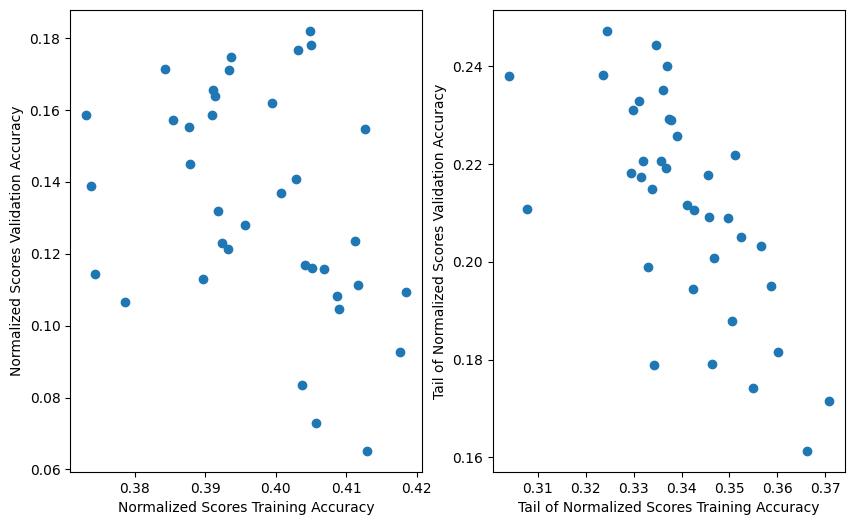

In [418]:
# Data where ligand is randomly chosen
# Extracted from output file
train_test_full_scores = [(0.41850970686995287, 0.10940572694867164), (0.3897325310651699, 0.11285710754319554), (0.40291124403440276, 0.1408534776326334), (0.4057407710044978, 0.0729906857715959), (0.4129811358058576, 0.0652098972123404), (0.41117205472869023, 0.1234633584680681), (0.39326814918835856, 0.12114845767530844), (0.3786711577551917, 0.10659697342804975), (0.40679425485745285, 0.11559431728234947), (0.39239119059443217, 0.12309018870322391), (0.40409223583666887, 0.11680822413895792), (0.3730977080505465, 0.158458281128244), (0.3936787184090276, 0.17468859775839368), (0.40079249892664726, 0.1369642095404109), (0.417615579184706, 0.09252744690554905), (0.3994390917351942, 0.1617464473435939), (0.3842351900174338, 0.17130969543263935), (0.4115816190356964, 0.11131024166093317), (0.39338736423454945, 0.1711362767796382), (0.4086199668362173, 0.1081998605234892), (0.37380601749848114, 0.13885367102719828), (0.408942808162629, 0.1046508069227528), (0.404980838754631, 0.17793364308378487), (0.39140642698414935, 0.1637203827796247), (0.40374003232515493, 0.0834059546711646), (0.4031266402202355, 0.1767431840127272), (0.38773896873146263, 0.1552967217058906), (0.41256668512658534, 0.15466336995914104), (0.39177413493863905, 0.13186088023705622), (0.3854586796927941, 0.1571303926539622), (0.37437114662882726, 0.11433789067715294), (0.3910307217978256, 0.16537051081199455), (0.3909530024401965, 0.15852221363967778), (0.39555891082326744, 0.12806054122082838), (0.38778717374272814, 0.1450166166680611), (0.40476960202410567, 0.1819644338010177), (0.4050552380713649, 0.11612674155006496)]
train_test_full_test = [scores[0] for scores in train_test_full_scores]
train_test_full_val = [scores[1] for scores in train_test_full_scores]
train_test_tail_scores = [(0.3342732602666904, 0.17899020986616992), (0.3565957123893169, 0.20313161208321343), (0.342554766792744, 0.2104847237532604), (0.33191124746088807, 0.22056027501029263), (0.34550698128081375, 0.21763499791584692), (0.3662266683618113, 0.16137949895373166), (0.35046221819934226, 0.18784568215426745), (0.3298234529782582, 0.231051727731933), (0.3497480579248997, 0.208951152282692), (0.3311575449881694, 0.23288315644543808), (0.34630143641865463, 0.17917824978460772), (0.3467758837109788, 0.2006892314142199), (0.3524267575012972, 0.20495369737778746), (0.34575706096270675, 0.2091613916865404), (0.30772217346013314, 0.21080968879959247), (0.370783961785899, 0.17162890065700848), (0.33623752162555165, 0.23507333260485197), (0.3586151286656987, 0.19499808471331423), (0.3411311943294526, 0.21158542773523295), (0.35496620953080316, 0.17418780875123818), (0.3367287048568735, 0.21921160059734224), (0.3235491228707458, 0.2380868291570708), (0.33460555756166377, 0.2442777981904938), (0.33163528268973175, 0.21735489457949078), (0.324457826373552, 0.24717787914700082), (0.351097276142478, 0.22170787404440456), (0.33581762536242454, 0.22056066250730497), (0.3294416153373024, 0.21814109545689392), (0.3424178816064962, 0.19437793218344446), (0.3378846281473651, 0.22897793516259485), (0.3601743265500692, 0.18145744037719078), (0.3040076745404206, 0.23802031011150615), (0.3369942091188325, 0.23996936496605384), (0.33394430636759465, 0.21490791095778836), (0.3374237689935133, 0.22907800315793972), (0.3389624597702203, 0.22571106568021881), (0.333108901576158, 0.19896124375444307)]
train_test_tail_test = [scores[0] for scores in train_test_tail_scores]
train_test_tail_val = [scores[1] for scores in train_test_tail_scores]

fig, axs = plt.subplots(1, 2)
axs[0].scatter(train_test_full_test, train_test_full_val)
axs[0].set_xlabel("Normalized Scores Training Accuracy")
axs[0].set_ylabel("Normalized Scores Validation Accuracy")
axs[1].scatter(train_test_tail_test, train_test_tail_val)
axs[1].set_xlabel("Tail of Normalized Scores Training Accuracy")
axs[1].set_ylabel("Tail of Normalized Scores Validation Accuracy")

fig.set_figwidth(10)
fig.set_figheight(6)

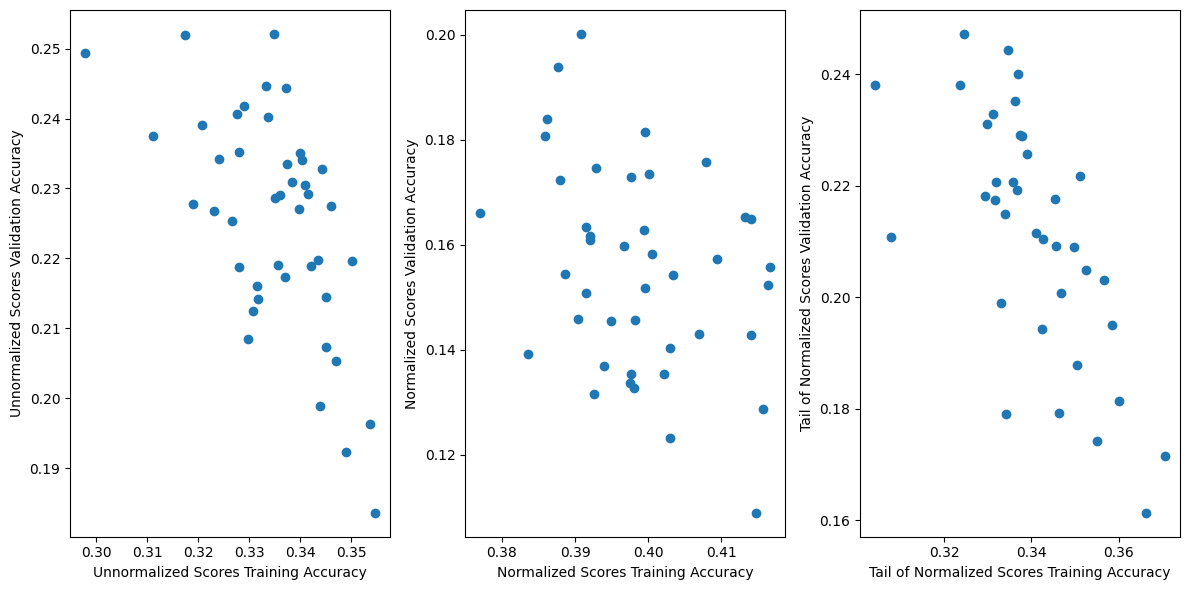

In [422]:
# Data where ligand is fixed
test_train_unnorm = [(0.32400322829036776, 0.2342597291689033), (0.32317346858227597, 0.22677786058102753), (0.3266747760456321, 0.22529016652162218), (0.3289069564633622, 0.24176154923737136), (0.33706918766177507, 0.2173377518601928), (0.33609991581635423, 0.22906304722630602), (0.3403687507298278, 0.23408737674100788), (0.3409803144933314, 0.23042203628672853), (0.31735827958478746, 0.2519503620308361), (0.3383266709881245, 0.23085361001143054), (0.327519261988374, 0.24063780783903077), (0.34205678055972916, 0.2188788457204135), (0.3374030898713151, 0.2334888865924313), (0.329714829845255, 0.20847477970064954), (0.3460720783231232, 0.22746579884608453), (0.33146051832574147, 0.21611701153175175), (0.34897369556808827, 0.19227688149898484), (0.3399925847898928, 0.23504735647350597), (0.3439246271200803, 0.19893716097192313), (0.3188925057248717, 0.2277839514489354), (0.3333069212899239, 0.244636790529634), (0.335024190467617, 0.22859679026786808), (0.353704610606838, 0.19625870892306552), (0.3502000325138739, 0.21958096611883093), (0.33573457632773335, 0.2191227881289935), (0.3397922655525039, 0.22705292976692254), (0.29773196269389773, 0.249383927219403), (0.32083079215538857, 0.2391205594325258), (0.3111490883779092, 0.23743431626588868), (0.3306614741591002, 0.21247176054860234), (0.337144433543649, 0.24440167910354083), (0.34346233536212806, 0.2197838470101514), (0.34707093573408365, 0.20531707164800392), (0.32799728586382043, 0.2187256047738158), (0.3443691516166777, 0.23283176946600526), (0.32804802920205844, 0.2352792432108326), (0.331661203554911, 0.2141780953686938), (0.34510795956211565, 0.21448295581201102), (0.3547771193145138, 0.18362664566988923), (0.34505179447746603, 0.20726730146371056), (0.34152831109436654, 0.2292585935697679), (0.33481207380520694, 0.25209109574129995), (0.3337920322221605, 0.24022237292796328)]
test_train_unnorm_test = [scores[0] for scores in test_train_unnorm]
test_train_unnorm_val = [scores[1] for scores in test_train_unnorm]
test_train_norm  = [(0.4021112416310827, 0.1354625848212809), (0.3974509814619437, 0.1336345688679083), (0.37695346641214045, 0.1659960126581688), (0.38584086249936433, 0.18061526403642886), (0.39951822894236255, 0.15184270052630536), (0.3876170434496796, 0.19385822295592534), (0.4000282583734263, 0.17346745034912603), (0.39762598836111473, 0.13547918286936514), (0.40294630069014065, 0.1231718183987642), (0.400504111193857, 0.15818546478539774), (0.39956832204592146, 0.18147360252460196), (0.39197792441147533, 0.1617447024051752), (0.40689036377724597, 0.1430508965085544), (0.3982363325983547, 0.14568460715570697), (0.415668685263752, 0.12882160799217718), (0.3926031346164189, 0.1316352734337835), (0.38863463393175846, 0.15446432772240892), (0.3878851936652117, 0.1722750735198884), (0.41406044401220055, 0.16498073339874036), (0.4166984605422037, 0.15572132323326915), (0.3908345515971172, 0.20013887868612307), (0.3975814362594599, 0.17286274594793277), (0.3915114975601838, 0.15078558754374785), (0.4132162734634709, 0.1653546777821835), (0.4147256725702713, 0.1089751486256049), (0.3862131993429453, 0.18391000464007967), (0.39151896670433595, 0.16329001319019115), (0.4033767006106227, 0.15416151163138717), (0.39493355687616183, 0.14546754278401108), (0.4163873052066806, 0.1523644515230645), (0.40296084835401896, 0.14028586420446743), (0.3967077252822414, 0.15968224572815404), (0.40784043395794856, 0.1758016542739923), (0.39806125322857144, 0.13269998166246105), (0.3919634199163569, 0.16083141844175858), (0.3904070869609515, 0.1458735911880476), (0.3835904691719567, 0.13914113529288843), (0.39947175776754273, 0.1628253318911314), (0.40940044021996047, 0.15720144339904196), (0.39401146140245585, 0.1370110392344452), (0.39288215354310807, 0.17468829634814825), (0.4139732234121952, 0.1428298254274335)]
test_train_norm_test = [scores[0] for scores in test_train_norm]
test_train_norm_val = [scores[1] for scores in test_train_norm]
test_train_tail = [(0.3286289061560957, 0.2300664886841517), (0.33894495035434935, 0.21767527901331102), (0.33204333622658155, 0.2234882626769616), (0.3350272307682679, 0.24067613070127053), (0.32101934986789143, 0.23958121238180685), (0.3297920141259984, 0.23949224094028862), (0.33082185057594465, 0.2380253754349523), (0.3605178357081726, 0.19794540963177953), (0.31841712990398663, 0.25862418413290134), (0.3291655712669877, 0.2530606937413858), (0.33306490855837245, 0.24277125179045062), (0.34241069546796876, 0.20493059350147222), (0.3362316254254057, 0.2180202450306838), (0.3456496166307504, 0.2136756212488552), (0.35192857131382954, 0.21159372197638132), (0.3223251868694569, 0.2251619016756273), (0.34710608303584894, 0.21917526082532024), (0.33383885030375116, 0.21254963411322847), (0.3530423762362336, 0.22491134964781), (0.33613318111793605, 0.22970905033172317), (0.31363495641317185, 0.21035965867139794), (0.3270074733783035, 0.233275835053989), (0.3153619591304441, 0.24575420785558422), (0.3414364610908673, 0.22268160683329424), (0.3270843514070157, 0.2320725013367608), (0.33622016710151215, 0.2292770823564444), (0.32797493355981633, 0.2227297867606732), (0.33548947253404476, 0.21525249447135147), (0.31243093104869896, 0.23085745364207988), (0.32340050560748856, 0.264089268656197), (0.31180305274592784, 0.260235618124546), (0.32472914043953455, 0.23216761281066903), (0.35498882894204364, 0.2020292977850828), (0.3375644488889258, 0.2107605123470983), (0.32258894764571566, 0.23512207750153677), (0.31869902551720447, 0.21617168871367332), (0.34050236445243864, 0.22106629547848547), (0.3184616683250121, 0.22377783099733015), (0.3198352023674224, 0.21727090384490075), (0.3406053892504399, 0.2297615254121708), (0.3488385206487373, 0.19983642676390892), (0.3390436815761276, 0.22850012186804386)]
test_train_tail_test = [scores[0] for scores in test_train_tail]
test_train_tail_val = [scores[1] for scores in test_train_tail]

fig, axs = plt.subplots(1, 3)
axs[0].scatter(test_train_unnorm_test, test_train_unnorm_val)
axs[0].set_xlabel("Unnormalized Scores Training Accuracy")
axs[0].set_ylabel("Unnormalized Scores Validation Accuracy")
axs[1].scatter(test_train_norm_test, test_train_norm_val)
axs[1].set_xlabel("Normalized Scores Training Accuracy")
axs[1].set_ylabel("Normalized Scores Validation Accuracy")
axs[2].scatter(train_test_tail_test, train_test_tail_val)
axs[2].set_xlabel("Tail of Normalized Scores Training Accuracy")
axs[2].set_ylabel("Tail of Normalized Scores Validation Accuracy")

fig.set_figwidth(12)
fig.set_figheight(6)
fig.tight_layout()

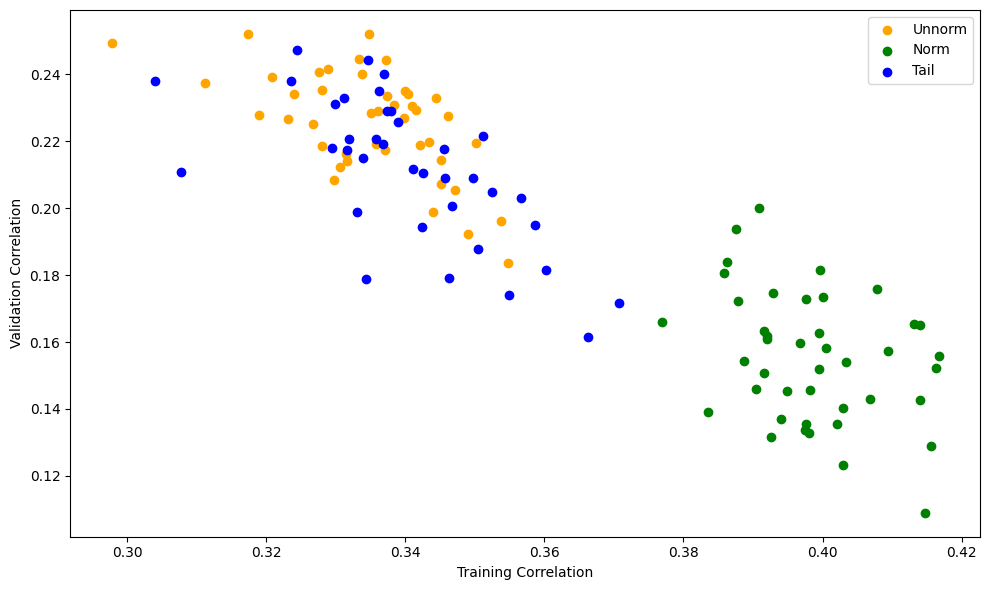

In [428]:
fig, ax = plt.subplots()
ax.scatter(test_train_unnorm_test, test_train_unnorm_val, color="orange", label="Unnorm")
ax.scatter(test_train_norm_test, test_train_norm_val, color="green", label="Norm")
ax.scatter(train_test_tail_test, train_test_tail_val, color="blue", label="Tail")
ax.set_xlabel("Training Correlation")
ax.set_ylabel("Validation Correlation")
ax.legend()

fig.set_figwidth(10)
fig.set_figheight(6)
fig.tight_layout()

## Distribution of model accuracies - You probably don't need to run this

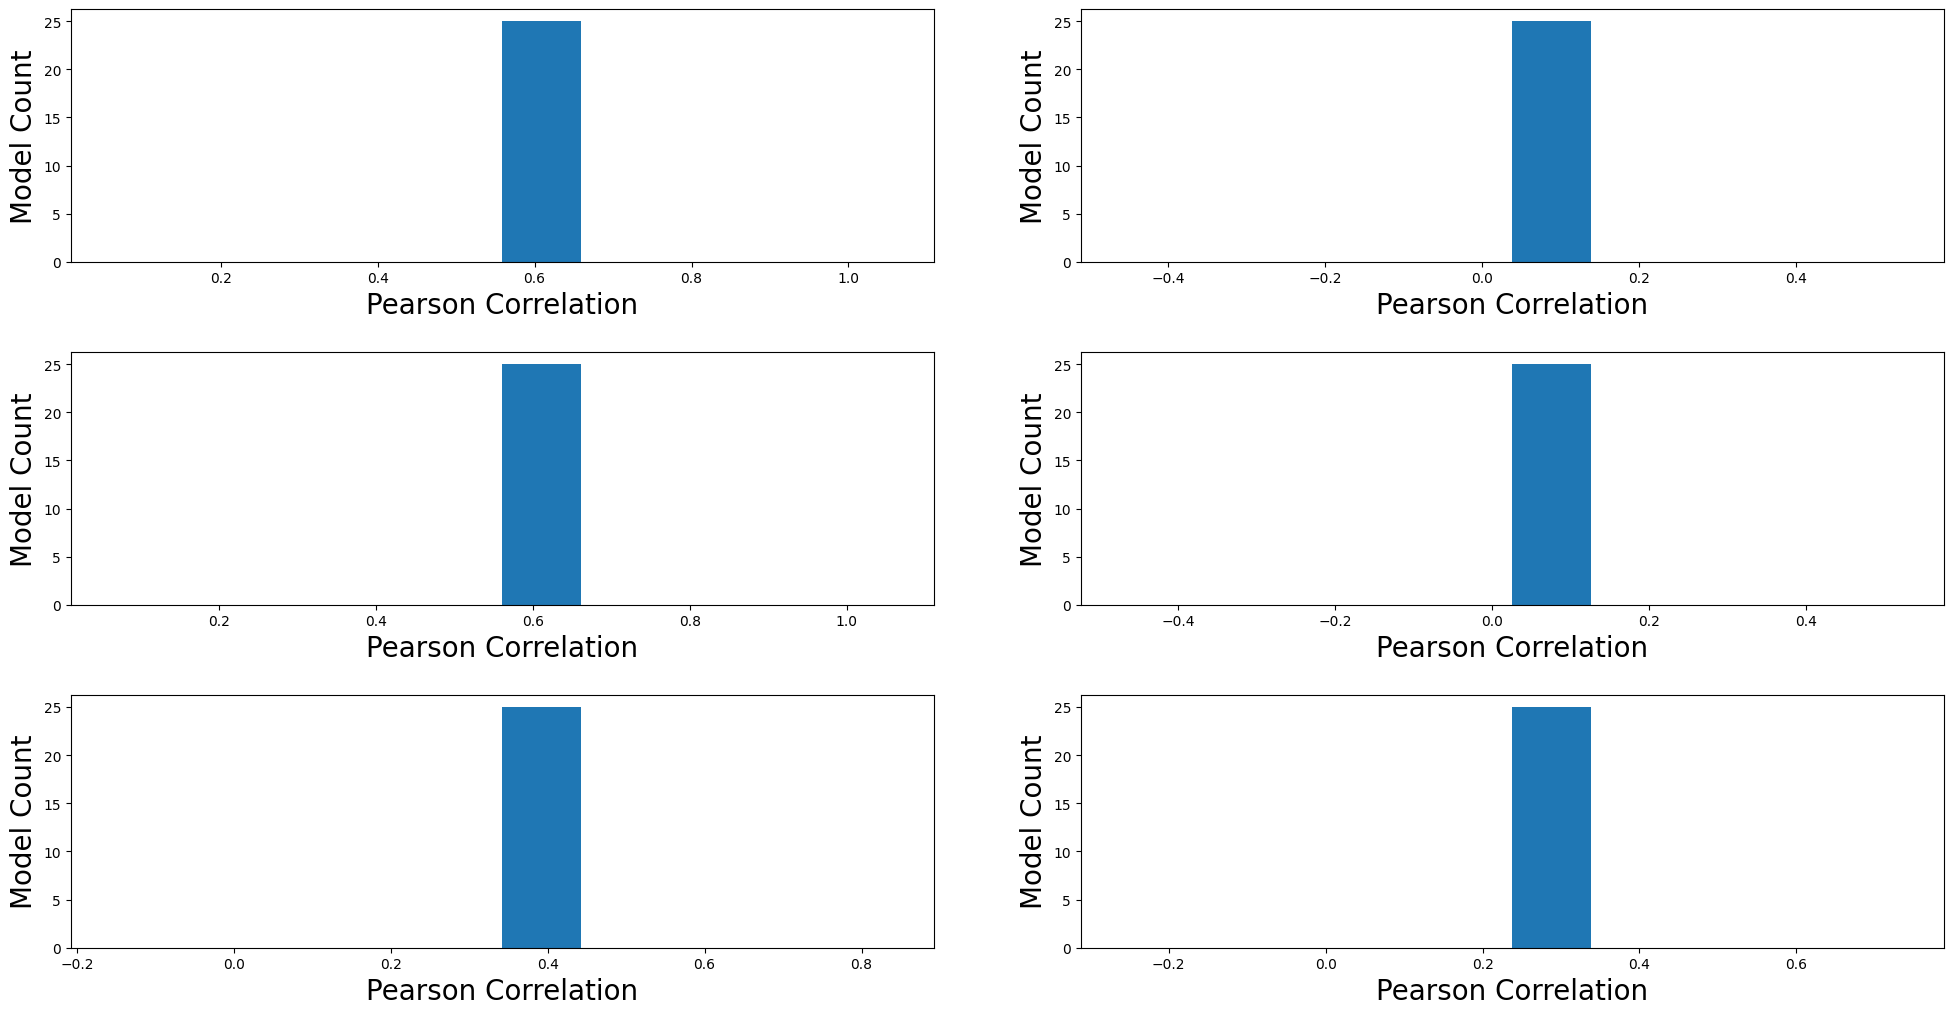

In [123]:
## Oops it's constant, there's no distribution. You probably don't need to run this

unnorm_scores = []
norm_scores = []
tail_scores = []
all_scores = [unnorm_scores, norm_scores, tail_scores]

ml_dir = Path("/Users/isaiahhazelwood/Documents/rotations-2024/fraser-lab/MET_kinase_Inhibitor_DMS/Machine_Learning/")

with open(ml_dir / "tune_and_train_run1.txt") as f_trainings:
    trainings_count = 0
    for line in f_trainings:
        if line.startswith("Train and test results:"):
            feat, mse_train, pearson_train, mse_test, pearson_test = line.rstrip("\n").split(",")
            all_scores[trainings_count % 3].append((float(pearson_train), float(pearson_test)))
            trainings_count += 1
        continue

fig, axs = plt.subplots(3, 2)
for i in range(len(all_scores)):
    train_scores = [pair[0] for pair in all_scores[i]]
    test_scores = [pair[1] for pair in all_scores[i]]
    axs[i, 0].hist(train_scores)
    axs[i, 0].set_xlabel("Pearson Correlation", size=20)
    axs[i, 0].set_ylabel("Model Count", size=20)

    axs[i, 1].hist(test_scores)
    axs[i, 1].set_xlabel("Pearson Correlation", size=20)
    axs[i, 1].set_ylabel("Model Count", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(10)

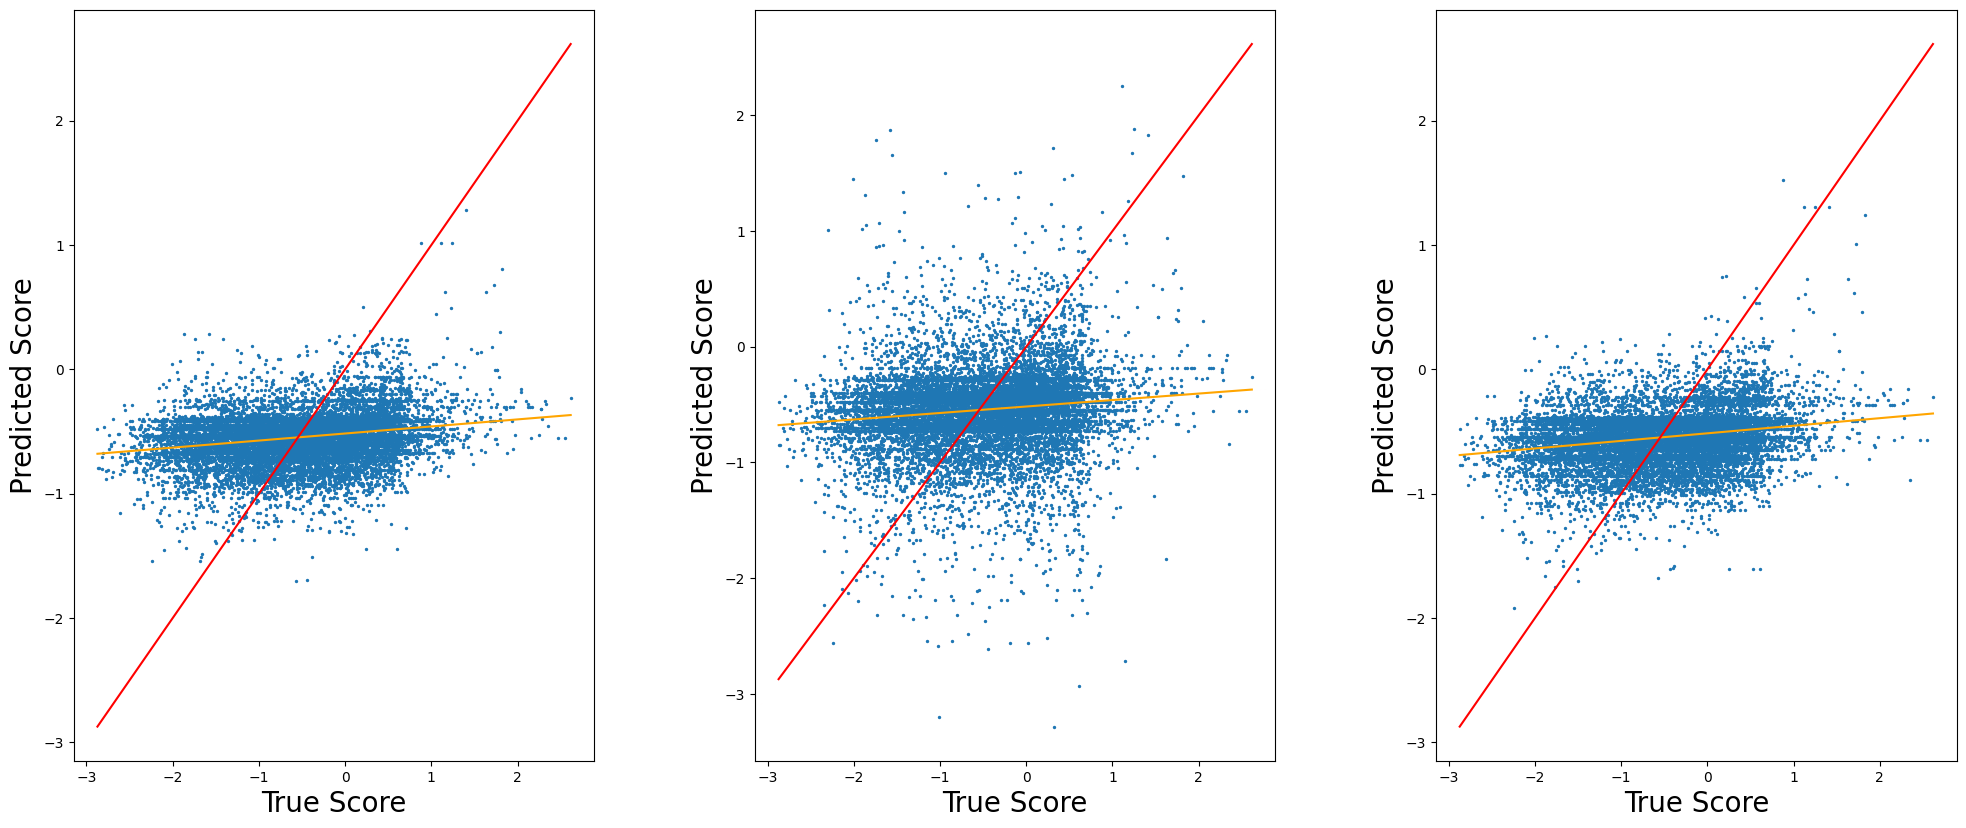

In [124]:
# Plot the correlation of scores predictions with score true values

unnorm_scores = []
unnorm_preds = []
with open(ml_dir / "features_prediction/unnorm/all_features_test_pred_run2.csv") as f_unnorm:
    for line in f_unnorm:
        unnorm_score, unnorm_pred = line.rstrip("\n").split(",")
        unnorm_scores.append(float(unnorm_score))
        unnorm_preds.append(float(unnorm_pred))

norm_scores = []
norm_preds = []
with open(ml_dir / "features_prediction/norm/all_features_norm_test_pred_run2.csv") as f_norm:
    for line in f_norm:
        norm_score, norm_pred = line.rstrip("\n").split(",")
        norm_scores.append(float(norm_score))
        norm_preds.append(float(norm_pred))

tail_scores = []
tail_preds = []
with open(ml_dir / "features_prediction/tail/all_features_norm_tail_test_pred_run2.csv") as f_tail:
    for line in f_tail:
        tail_score, tail_pred = line.rstrip("\n").split(",")
        tail_scores.append(float(tail_score))
        tail_preds.append(float(tail_pred))

datasets = [(unnorm_scores, unnorm_preds), (norm_scores, norm_preds), (tail_scores, tail_preds)]
fig, axs = plt.subplots(1, 3)
for i in range(len(datasets)):
    axs[i].scatter(datasets[i][0], datasets[i][1], s=2)

    m, b = np.polyfit(datasets[i][0], datasets[i][1], deg=1)
    best_x = np.linspace(np.min(datasets[i][0]), np.max(datasets[i][0]), num=100)
    best_y = m * best_x + b
    axs[i].plot(best_x, best_y, color="orange")
    axs[i].plot(best_x, best_x, color="red")
    # print(stats.pearsonr(datasets[i][0], datasets[i][1]))
    
    axs[i].set_xlabel("True Score", size=20)
    axs[i].set_ylabel("Predicted Score", size=20)

fig.tight_layout(pad=-1)
fig.set_figwidth(20)
fig.set_figheight(8)

## Compare ESM2 Predictions with Scores - You probably don't need to run this

In [214]:
# ESM scores describe wild type fitness, so should not correlate with scores
# These files are on castor, are not uploaded to Github

esm2_pred_dir = Path("/Users/isaiahhazelwood/Documents/rotations-2024/fraser-lab/MLP/esm_pred")
# esm1b_pred_dir = Path("/Users/isaiahhazelwood/Documents/rotations-2024/fraser-lab/MLP/esm1b_pred")

def read_esm_scores(filename, directory=esm2_pred_dir):
    esm_scores = {}
    with open(directory / filename) as f_pred:
        line = f_pred.readline() # Skip header
        line = f_pred.readline()
        while line != "":
            cols = line.rstrip("\n").split(",")
            wt = cols[3]
            pos = int(cols[4])
            mut = cols[5]
            score = float(cols[6])
            esm_scores[(wt, pos, mut)] = score
            line = f_pred.readline()
    return esm_scores

CDK4_esm_scores = read_esm_scores("CDK4_pred.csv")
CDK6_esm_scores = read_esm_scores("CDK6_pred.csv")
EGFR_esm_scores = read_esm_scores("EGFR_pred.csv")
# EGFR_esm_scores = {(wt, pos + 650, mut): EGFR_esm_scores[(wt, pos, mut)] 
#                    for (wt, pos, mut) in EGFR_esm_scores}
EGFR_T790M_esm_scores = read_esm_scores("EGFR_T790M_pred.csv")
# EGFR_T790M_esm_scores = {(wt, pos + 650, mut): EGFR_T790M_esm_scores[(wt, pos, mut)] 
#                          for (wt, pos, mut) in EGFR_T790M_esm_scores}
MET_dEx14_esm_scores = read_esm_scores("MET_dEx14_pred.csv")
# MET_dEx14_esm_scores = {(wt, pos + 995, mut): MET_dEx14_esm_scores[(wt, pos, mut)] 
#                         for (wt, pos, mut) in MET_dEx14_esm_scores}
MET_WT_esm_scores = read_esm_scores("MET_WT_pred.csv")
# MET_WT_esm_scores = {(wt, pos + 1050, mut): MET_WT_esm_scores[(wt, pos, mut)] 
#                      for (wt, pos, mut) in MET_WT_esm_scores}
SRC_esm_scores = read_esm_scores("SRC_pred.csv")

In [223]:
# Load esm scores from webserver CSV
esm_server_dir = Path("/Users/isaiahhazelwood/Documents/rotations-2024/fraser-lab/MLP/esm_server")

def read_server_esm_scores(filename, directory=esm_server_dir):
    esm_scores = {}
    with open(directory / filename) as f_pred:
        line = f_pred.readline() # Skip header
        line = f_pred.readline()
        while line != "":
            cols = line.rstrip("\n").split(",")
            wt = cols[0][0]
            pos = int(cols[2])
            mut = cols[0][-1]
            score = float(cols[1])
            esm_scores[(wt, pos, mut)] = score
            line = f_pred.readline()
    return esm_scores

CDK4_esm_scores = read_server_esm_scores("CDK4_P11802.csv")
CDK6_esm_scores = read_server_esm_scores("CDK6_Q00534.csv")
EGFR_esm_scores = read_server_esm_scores("EGFR_P00533.csv")
# EGFR_esm_scores = {(wt, pos + 650, mut): EGFR_esm_scores[(wt, pos, mut)] 
#                    for (wt, pos, mut) in EGFR_esm_scores}
# EGFR_T790M_esm_scores = read_esm_scores("EGFR_T790M_pred.csv")
# EGFR_T790M_esm_scores = {(wt, pos + 650, mut): EGFR_T790M_esm_scores[(wt, pos, mut)] 
#                          for (wt, pos, mut) in EGFR_T790M_esm_scores}
# MET_dEx14_esm_scores = read_esm_scores("MET_dEx14_pred.csv")
# MET_dEx14_esm_scores = {(wt, pos + 995, mut): MET_dEx14_esm_scores[(wt, pos, mut)] 
#                         for (wt, pos, mut) in MET_dEx14_esm_scores}
MET_WT_esm_scores = read_server_esm_scores("MET_P08581.csv")
# MET_WT_esm_scores = {(wt, pos + 1050, mut): MET_WT_esm_scores[(wt, pos, mut)] 
#                      for (wt, pos, mut) in MET_WT_esm_scores}
SRC_esm_scores = read_server_esm_scores("SRC_P12931.csv")

In [224]:
def load_scores(filename, directory=difference_dir, sep=","):
    """
    Load scores from a csv file as a dictionary of {(wt, position, mut): score}.
    filename: file name within the raw-data directory
    keep_cols: 0-indexed list of columns to record
    header: number of header lines to skip
    """
    scores = {}
    with open(directory / filename, "r") as f_scores:
        for line_num, line in enumerate(f_scores):
            if line_num < 1: # Skip header
                continue
            prot, ligand, wt, pos, mut, score = line.rstrip("\n").split(sep)
            pos = int(pos)
            score = float(score)
            scores[(prot, ligand, wt, pos, mut)] = score
    return scores

cdk4_persky = load_scores("CDK4_Persky_2020.csv")
cdk6_persky = load_scores("CDK6_Persky_2020.csv")
EGFR_An = load_scores("EGFR_An_2022.csv")
EGFR_Hayes = load_scores("EGFR_Hayes_2024.csv")
EGFR_Kim = load_scores("EGFR_Kim_2024.csv")
EGFR_Kim.pop(("EGFR_T790M", "Osi_8nM", "T", 790, "M"), None)
EGFR_Kim.pop(("EGFR_T790M", "Afa_3nM", "T", 790, "M"), None)
MET_dEx14_Estevam = load_scores("MET_Estevam_2024_dEx14.csv")
MET_WT_Estevam = load_scores("MET_Estevam_2024_WT.csv")
SRC_Chakraborty = load_scores("SRC_Chakraborty_2024.csv")

CDK4_Persky_2020 under treatment Pal_2uM Pearson R: -0.14938845752765179
CDK6_Persky_2020 under treatment Pal_2uM Pearson R: 0.19178029411870756
EGFR_An_2022 under treatment Afa_50nM Pearson R: 0.0074206553244012576
EGFR_An_2022 under treatment Osi_200nM Pearson R: -0.013954452712994973
EGFR_An_2022 under treatment Gef_600nM Pearson R: 0.008279718584173049
EGFR_An_2022 under treatment Erl_600nM Pearson R: 0.009148953460074872
EGFR_An_2022 under treatment Ico_600nM Pearson R: 0.0069776727471696064
EGFR_Hayes_2024 under treatment Erl_200nM Pearson R: 0.05153138374704634
EGFR_Kim_2024 under treatment Afa_3nM Pearson R: 0.20990062791317474
EGFR_Kim_2024 under treatment Osi_8nM Pearson R: 0.22151727911861804
SRC_Chakraborty_2024 under treatment Inhib1_8uM Pearson R: -0.12689191764234006
SRC_Chakraborty_2024 under treatment Inhib2_2uM Pearson R: -0.15862397151644925
SRC_Chakraborty_2024 under treatment Inhib4_0.8uM Pearson R: -0.12828804891722195
SRC_Chakraborty_2024 under treatment Dis_25uM

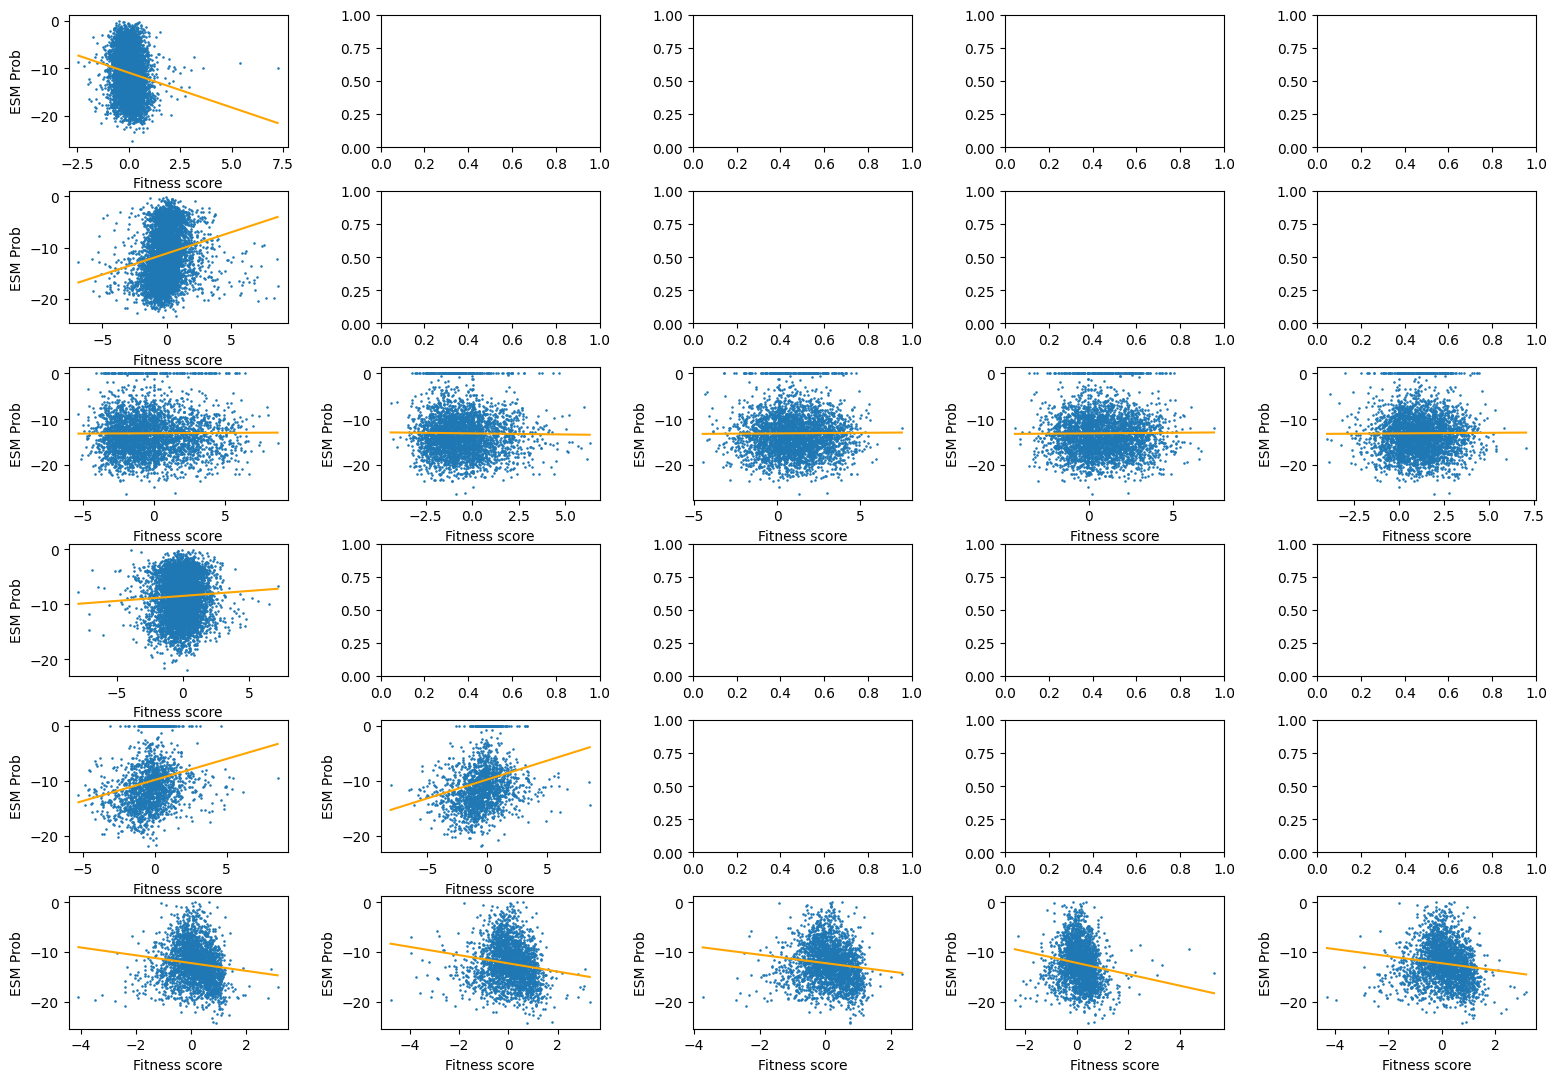

In [226]:
esm_datasets = {"CDK4": CDK4_esm_scores,
                "CDK6": CDK6_esm_scores,
                "EGFR": EGFR_esm_scores,
                # "EGFR_T790M": EGFR_T790M_esm_scores, 
                "SRC": SRC_esm_scores, 
                "MET_WT": MET_WT_esm_scores} 
                # "MET_dEx14": MET_dEx14_esm_scores}
score_datasets = [cdk4_persky, cdk6_persky, EGFR_An, EGFR_Hayes, EGFR_Kim, 
                  SRC_Chakraborty]
dataset_names = ["CDK4_Persky_2020", "CDK6_Persky_2020", "EGFR_An_2022", 
                 "EGFR_Hayes_2024", "EGFR_Kim_2024",
                 "SRC_Chakraborty_2024"]
treatments = [set(ligand for prot, ligand, wt, pos, mut in dataset) for dataset in score_datasets]

fig, axs = plt.subplots(6, 5)

for dataset_i, dataset in enumerate(score_datasets):
    for treatment_i, treatment in enumerate(treatments[dataset_i]):
        esm_scores = []
        true_scores = []
        for prot, ligand, wt, pos, mut in dataset:
            if ligand == treatment and prot in esm_datasets:
                if (wt, pos, mut) in esm_datasets[prot] and esm_datasets[prot][(wt, pos, mut)] <= 0:
                    esm_scores.append(esm_datasets[prot][(wt, pos, mut)])
                    true_scores.append(dataset[(prot, ligand, wt, pos, mut)])
        m, b = np.polyfit(true_scores, esm_scores, deg=1)
        fit_x = np.linspace(min(true_scores), max(true_scores), num=100)
        fit_y = m * fit_x + b
        axs[dataset_i, treatment_i].scatter(true_scores, esm_scores, s=0.7)
        axs[dataset_i, treatment_i].plot(fit_x, fit_y, color="orange")
        axs[dataset_i, treatment_i].set_xlabel("Fitness score")
        axs[dataset_i, treatment_i].set_ylabel("ESM Prob")
        r = stats.pearsonr(esm_scores, true_scores)[0].item()
        print(f"{dataset_names[dataset_i]} under treatment {treatment} Pearson R: {r}")

fig.tight_layout(pad=-2)
fig.set_figwidth(15)
fig.set_figheight(10)

MET_dEx14_Estevam_2024 under treatment Mere_47.3nM Pearson R: 0.1518141941040979
MET_dEx14_Estevam_2024 under treatment Cabo_71nM Pearson R: 0.10379725131894915
MET_dEx14_Estevam_2024 under treatment Tiv_2.55uM Pearson R: 0.16443135858790642
MET_dEx14_Estevam_2024 under treatment Glu_31.3nM Pearson R: 0.09854124261677734
MET_dEx14_Estevam_2024 under treatment NVP_45.1nM Pearson R: 0.06445402888309418
MET_dEx14_Estevam_2024 under treatment Tepo_1.74nM Pearson R: 0.0775812862551237
MET_dEx14_Estevam_2024 under treatment A458_534nM Pearson R: 0.14866836621877247
MET_dEx14_Estevam_2024 under treatment Crizo_21.9nM Pearson R: 0.12265636672926397
MET_dEx14_Estevam_2024 under treatment Camp_6.70nM Pearson R: 0.10203344111017351
MET_dEx14_Estevam_2024 under treatment Savo_1.51nM Pearson R: 0.09100932687043223
MET_dEx14_Estevam_2024 under treatment Gle_324nM Pearson R: 0.12145464584227861


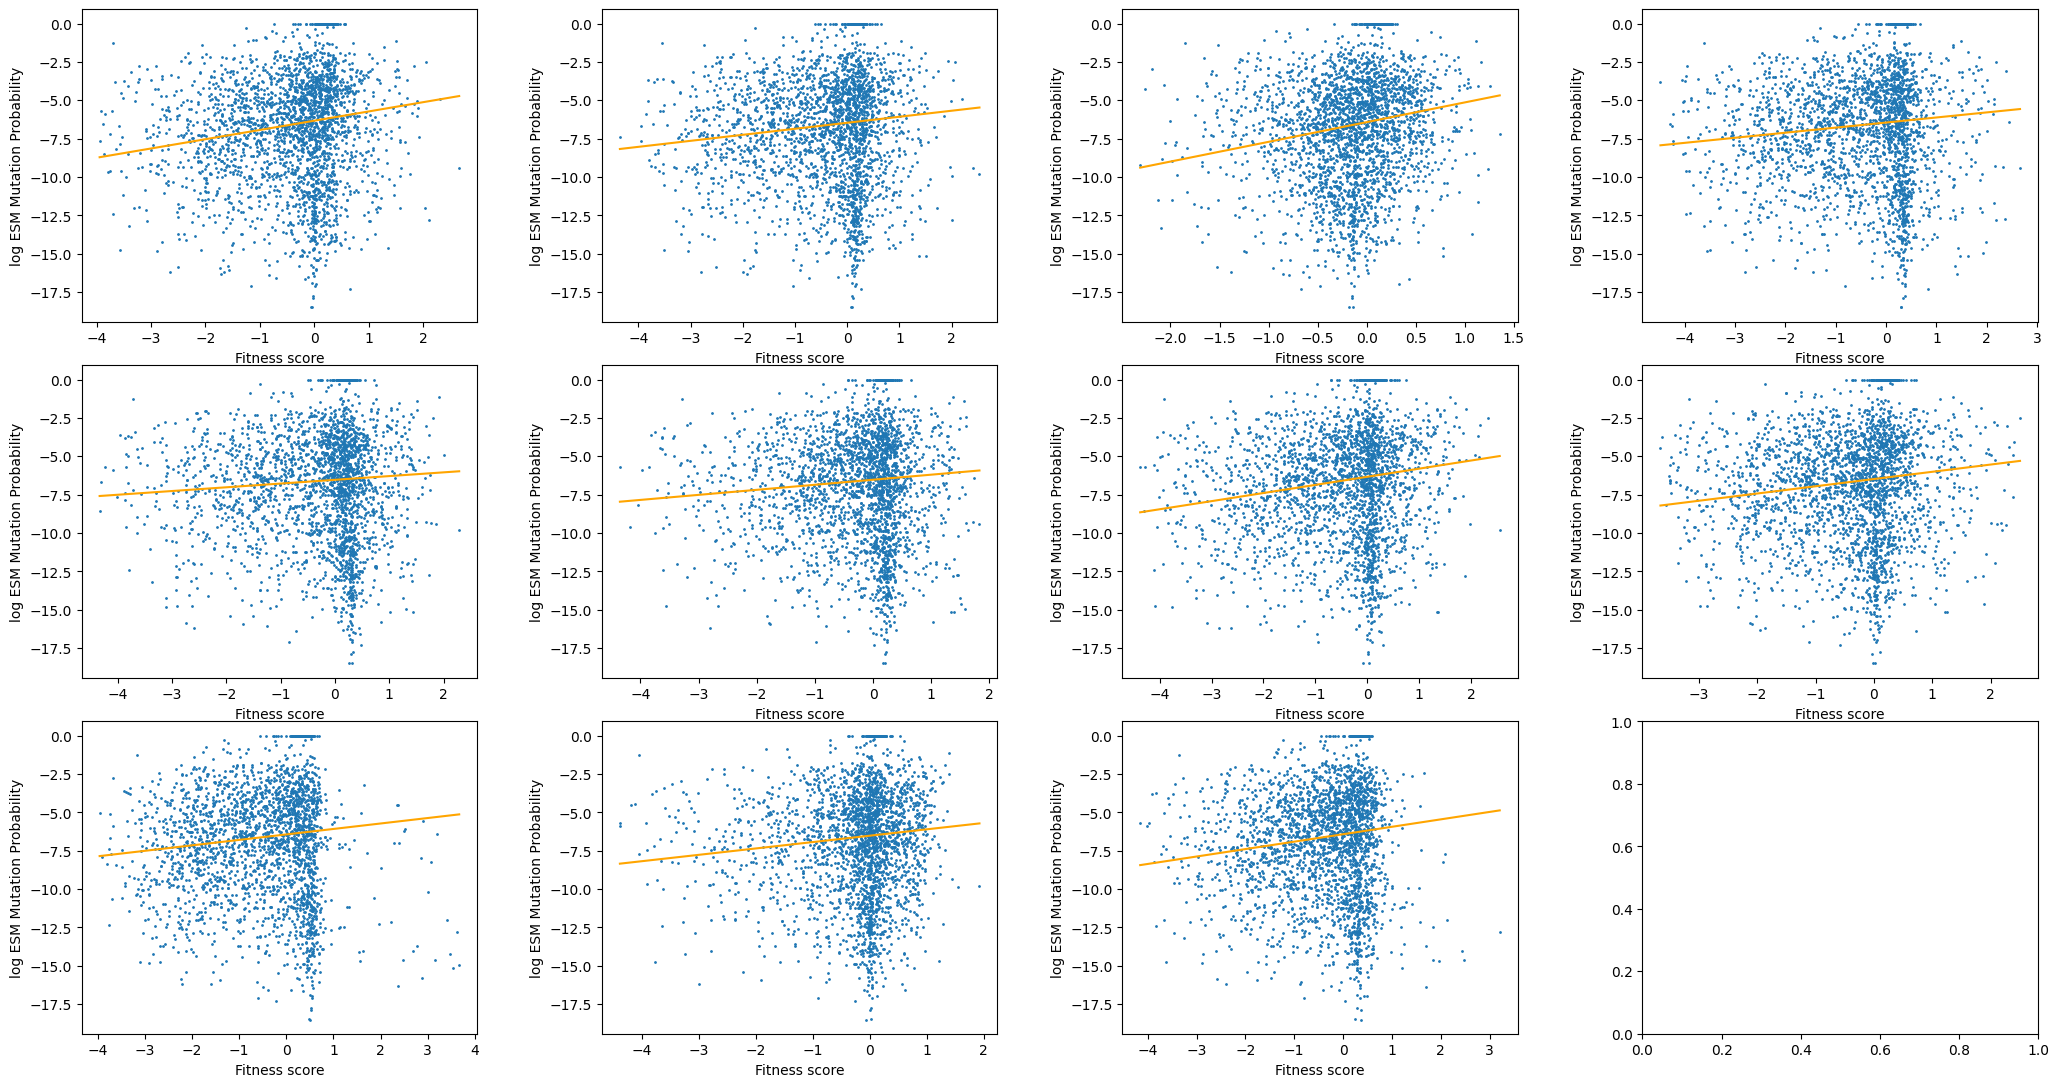

In [227]:
esm_datasets = {"CDK4": CDK4_esm_scores,
                "CDK6": CDK6_esm_scores,
                "EGFR": EGFR_esm_scores,
                "EGFR_T790M": EGFR_T790M_esm_scores, 
                "SRC": SRC_esm_scores, 
                "MET_WT": MET_WT_esm_scores, 
                "MET_dEx14": MET_dEx14_esm_scores}
score_datasets = [MET_dEx14_Estevam, MET_WT_Estevam]
dataset_names = ["MET_dEx14_Estevam_2024", "MET_WT_Estevam_2024"]
treatments = [set(ligand for prot, ligand, wt, pos, mut in dataset) for dataset in score_datasets]

fig, axs = plt.subplots(3, 4)
dataset_i, dataset = 0, MET_dEx14_Estevam
for treatment_i, treatment in enumerate(treatments[dataset_i]):
    esm_scores = []
    true_scores = []
    for prot, ligand, wt, pos, mut in dataset:
        if ligand == treatment:
            if (wt, pos, mut) in esm_datasets[prot] and esm_datasets[prot][(wt, pos, mut)] <= 0:
                esm_scores.append(esm_datasets[prot][(wt, pos, mut)])
                true_scores.append(dataset[(prot, ligand, wt, pos, mut)])
    m, b = np.polyfit(true_scores, esm_scores, deg=1)
    fit_x = np.linspace(min(true_scores), max(true_scores), num=100)
    fit_y = m * fit_x + b
    axs[treatment_i // 4, treatment_i % 4].scatter(true_scores, esm_scores, s=1)
    axs[treatment_i // 4, treatment_i % 4].plot(fit_x, fit_y, color="orange")
    axs[treatment_i // 4, treatment_i % 4].set_xlabel("Fitness score")
    axs[treatment_i // 4, treatment_i % 4].set_ylabel("log ESM Mutation Probability")
    r = stats.pearsonr(esm_scores, true_scores)[0].item()
    print(f"{dataset_names[dataset_i]} under treatment {treatment} Pearson R: {r}")

fig.tight_layout(pad=-2)
fig.set_figwidth(20)
fig.set_figheight(10)

MET_WT_Estevam_2024 under treatment Mere_47.3nM Pearson R: -0.13264637933986945
MET_WT_Estevam_2024 under treatment Cabo_71nM Pearson R: -0.030178371135818047
MET_WT_Estevam_2024 under treatment Tiv_2.55uM Pearson R: -0.006007788832166123
MET_WT_Estevam_2024 under treatment Glu_31.3nM Pearson R: -0.005739720089767803
MET_WT_Estevam_2024 under treatment NVP_45.1nM Pearson R: -0.07424888175706826
MET_WT_Estevam_2024 under treatment Tepo_1.74nM Pearson R: -0.004262099259398228
MET_WT_Estevam_2024 under treatment A458_534nM Pearson R: -0.10889333201599716
MET_WT_Estevam_2024 under treatment Crizo_21.9nM Pearson R: -0.08618659816027535
MET_WT_Estevam_2024 under treatment Camp_6.70nM Pearson R: -0.19234118263179567
MET_WT_Estevam_2024 under treatment Savo_1.51nM Pearson R: 0.06982217925320966
MET_WT_Estevam_2024 under treatment Gle_324nM Pearson R: -0.16758849505171203


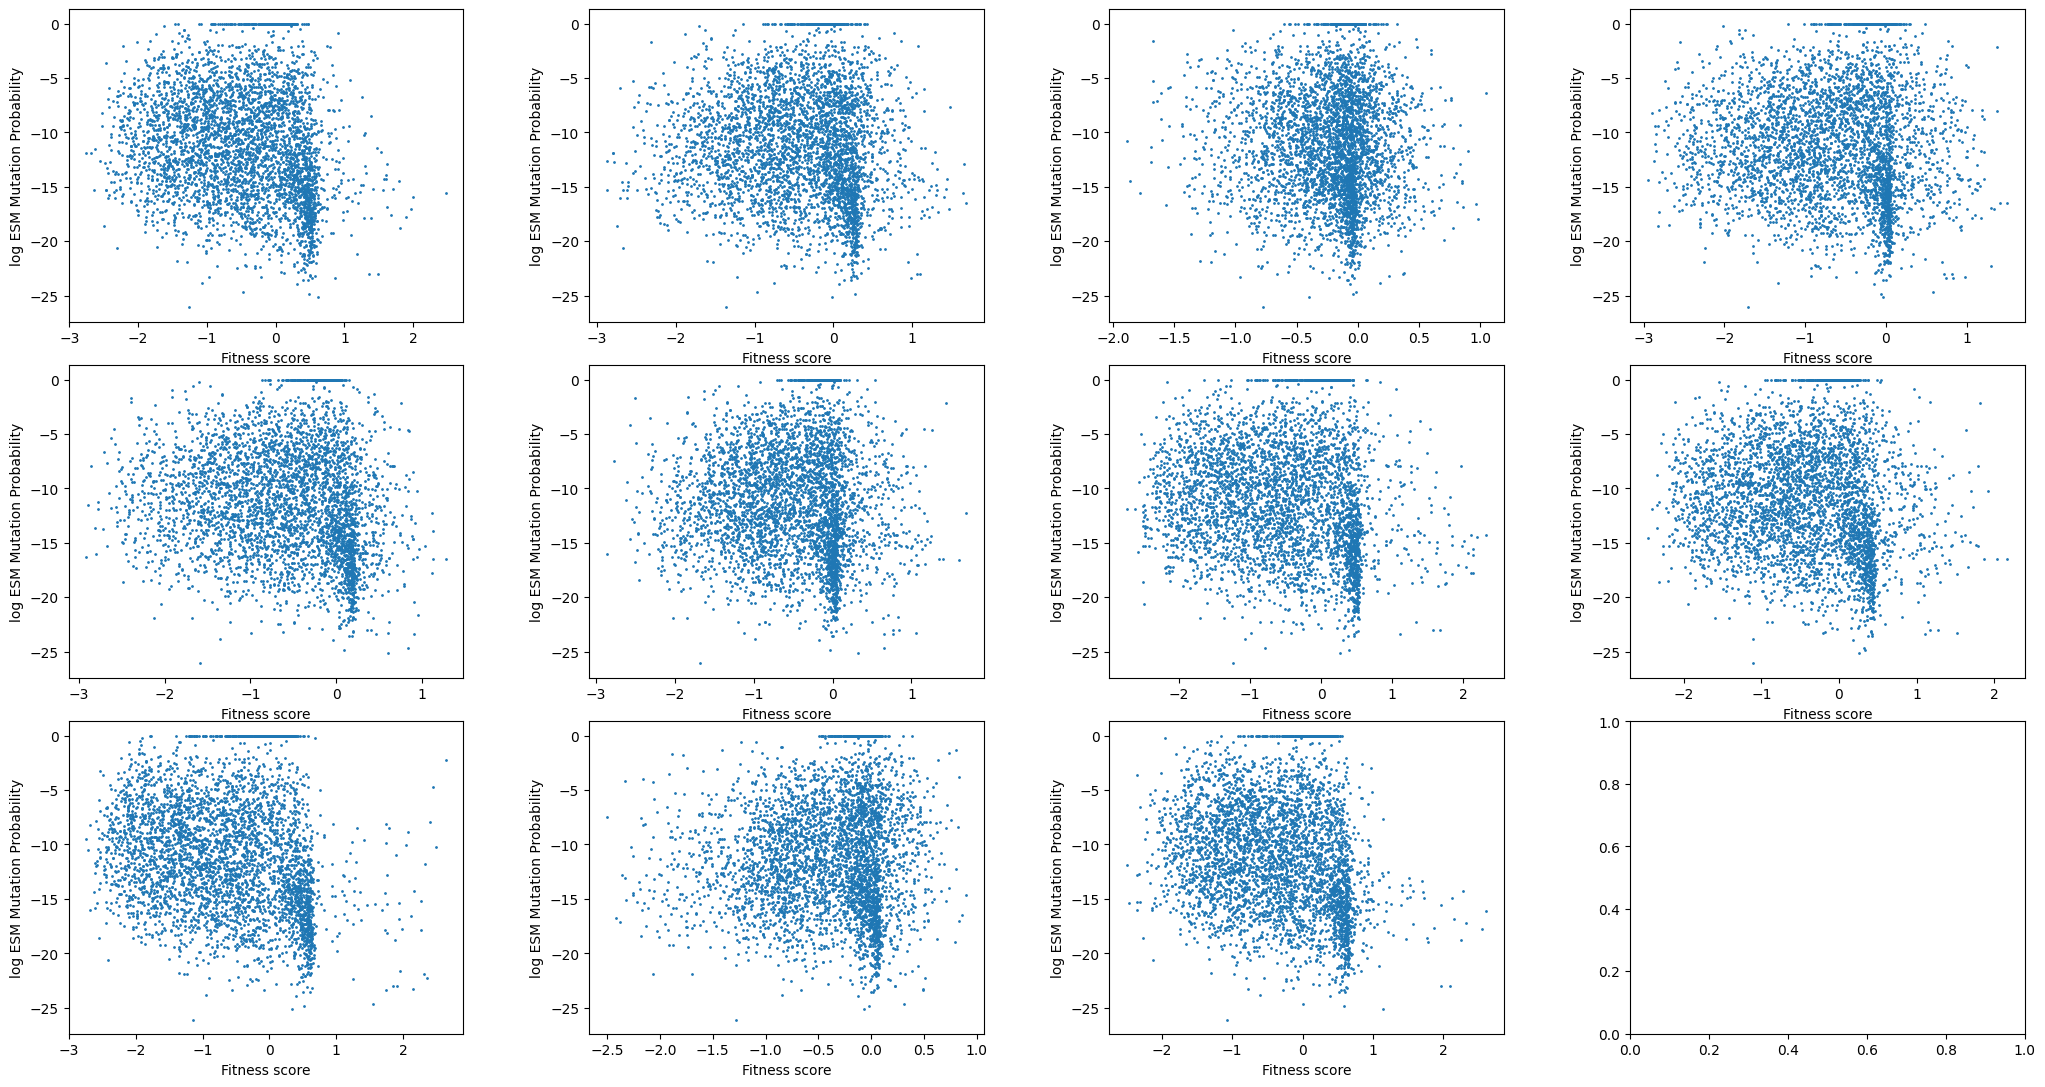

In [229]:
esm_datasets = {"CDK4": CDK4_esm_scores,
                "CDK6": CDK6_esm_scores,
                "EGFR": EGFR_esm_scores,
                "EGFR_T790M": EGFR_T790M_esm_scores, 
                "SRC": SRC_esm_scores, 
                "MET_WT": MET_WT_esm_scores, 
                "MET_dEx14": MET_dEx14_esm_scores}
score_datasets = [MET_dEx14_Estevam, MET_WT_Estevam]
dataset_names = ["MET_dEx14_Estevam_2024", "MET_WT_Estevam_2024"]
treatments = [set(ligand for prot, ligand, wt, pos, mut in dataset) for dataset in score_datasets]

fig, axs = plt.subplots(3, 4)
dataset_i, dataset = 1, MET_WT_Estevam
for treatment_i, treatment in enumerate(treatments[dataset_i]):
    esm_scores = []
    true_scores = []
    for prot, ligand, wt, pos, mut in dataset:
        if ligand == treatment:
            if (wt, pos, mut) in esm_datasets[prot] and esm_datasets[prot][(wt, pos, mut)] <= 0:
                esm_scores.append(esm_datasets[prot][(wt, pos, mut)])
                true_scores.append(dataset[(prot, ligand, wt, pos, mut)])
    m, b = np.polyfit(true_scores, esm_scores, deg=1)
    fit_x = np.linspace(min(true_scores), max(true_scores), num=100)
    fit_y = m * fit_x + b
    axs[treatment_i // 4, treatment_i % 4].scatter(true_scores, esm_scores, s=1)
    # axs[treatment_i // 4, treatment_i % 4].plot(fit_x, fit_y, color="orange")
    axs[treatment_i // 4, treatment_i % 4].set_xlabel("Fitness score")
    axs[treatment_i // 4, treatment_i % 4].set_ylabel("log ESM Mutation Probability")
    r = stats.pearsonr(esm_scores, true_scores)[0].item()
    print(f"{dataset_names[dataset_i]} under treatment {treatment} Pearson R: {r}")

fig.tight_layout(pad=-2)
fig.set_figwidth(20)
fig.set_figheight(10)

## Generate defattr to show commonly mutated residues structurally - You probably don't need to run this

In [150]:
def load_scores(filename, directory=difference_dir, sep=","):
    """
    Load scores from a csv file as a dictionary of {(wt, position, mut): score}.
    filename: file name within the raw-data directory
    keep_cols: 0-indexed list of columns to record
    header: number of header lines to skip
    """
    scores = {}
    with open(directory / filename, "r") as f_scores:
        for line_num, line in enumerate(f_scores):
            if line_num < 1: # Skip header
                continue
            prot, ligand, wt, pos, mut, score = line.rstrip("\n").split(sep)
            pos = int(pos)
            score = float(score)
            scores[(prot, ligand, wt, pos, mut)] = score
    return scores

In [151]:
cdk4_persky = load_scores("CDK4_Persky_2020.csv")
cdk6_persky = load_scores("CDK6_Persky_2020.csv")
EGFR_An = load_scores("EGFR_An_2022.csv")
EGFR_Hayes = load_scores("EGFR_Hayes_2024.csv")
EGFR_Kim = load_scores("EGFR_Kim_2024.csv")
MET_dEx14_Estevam = load_scores("MET_Estevam_2024_dEx14.csv")
MET_WT_Estevam = load_scores("MET_Estevam_2024_WT.csv")
SRC_Chakraborty = load_scores("SRC_Chakraborty_2024.csv")

In [154]:
def extract_mean_scores(data, extract_prot, extract_ligand):
    mean_scores = {}
    for prot, ligand, wt, pos, mut in data:
        if prot == extract_prot and ligand == extract_ligand:
            if pos in mean_scores:
                mean_scores[pos].append(data[(prot, ligand, wt, pos, mut)])
            else:
                mean_scores[pos] = [data[(prot, ligand, wt, pos, mut)]]
    for key in mean_scores:
        mean_scores[key] = np.mean(mean_scores[key])
    return mean_scores

def write_defattr(file_output, mean_scores):
    with open(file_output, "w") as f_out:
        f_out.write("attribute: activity\n")
        f_out.write("recipient: residues\n")
        for pos in mean_scores:
            f_out.write(f"\t:{pos}\t{mean_scores[pos]}\n")

structure_dir = main_dir / "structures/"

EGFR_Afa_An = extract_mean_scores(EGFR_An, "EGFR", "Afa_50nM")
write_defattr(structure_dir / "EGFR_Afa_An.defattr", EGFR_Afa_An)
EGFR_Erl_An = extract_mean_scores(EGFR_An, "EGFR", "Erl_600nM")
write_defattr(structure_dir / "EGFR_Erl_An.defattr", EGFR_Erl_An)
EGFR_Osi_An = extract_mean_scores(EGFR_An, "EGFR", "Osi_200nM")
write_defattr(structure_dir / "EGFR_Osi_An.defattr", EGFR_Osi_An)

EGFR_Erl_Hayes = extract_mean_scores(EGFR_Hayes, "EGFR", "Erl_200nM")
write_defattr(structure_dir / "EGFR_Erl_Hayes.defattr", EGFR_Erl_Hayes)

EGFR_Afa_Kim = extract_mean_scores(EGFR_Kim, "EGFR", "Afa_3nM")
write_defattr(structure_dir / "EGFR_Afa_Kim.defattr", EGFR_Afa_Kim)
EGFR_Osi_Kim = extract_mean_scores(EGFR_Kim, "EGFR", "Osi_8nM")
write_defattr(structure_dir / "EGFR_Osi_Kim.defattr", EGFR_Osi_Kim)

In [142]:
print(min(pos for wt, pos, mut in EGFR_Afa_An), max(pos for wt, pos, mut in EGFR_Afa_An))
print(min(pos for wt, pos, mut in EGFR_Erl_An), max(pos for wt, pos, mut in EGFR_Erl_An))
print(min(pos for wt, pos, mut in EGFR_Osi_An), max(pos for wt, pos, mut in EGFR_Osi_An))

print(min(pos for wt, pos, mut in EGFR_Erl_Hayes), max(pos for wt, pos, mut in EGFR_Erl_Hayes))

print(min(pos for wt, pos, mut in EGFR_Afa_Kim), max(pos for wt, pos, mut in EGFR_Afa_Kim))
print(min(pos for wt, pos, mut in EGFR_Osi_Kim), max(pos for wt, pos, mut in EGFR_Osi_Kim))

687 874
687 874
687 874
16 1209
688 981
688 981


In [156]:
MET_WT_Estevam_tail = load_scores("MET_Estevam_2024_WT_tail.csv", directory=difference_tail_dir)

def extract_resistance_count(data, extract_prot, extract_ligand):
    resistance_counts = {}
    for prot, ligand, wt, pos, mut in data:
        if prot == extract_prot and ligand == extract_ligand and data[(prot, ligand, wt, pos, mut)] > 0:
            if pos in resistance_counts:
                resistance_counts[pos] += 1
            else:
                resistance_counts[pos] = 1
    return resistance_counts

MET_WT_A458_Estevam_counts = extract_resistance_count(MET_WT_Estevam_tail, "MET_WT", "A458_534nM")
write_defattr(structure_dir / "MET_WT_A458_counts.defattr", MET_WT_A458_Estevam_counts)
MET_WT_Crizo_Estevam_counts = extract_resistance_count(MET_WT_Estevam_tail, "MET_WT", "Crizo_21.9nM")
write_defattr(structure_dir / "MET_WT_Crizo_counts.defattr", MET_WT_Crizo_Estevam_counts)
MET_WT_Mere_Estevam_counts = extract_resistance_count(MET_WT_Estevam_tail, "MET_WT", "Mere_47.3nM")
write_defattr(structure_dir / "MET_WT_Mere_counts.defattr", MET_WT_Mere_Estevam_counts)